# ToysAD-8K full dataset exploratory data analysis

This notebook audits the complete validated ToysAD-8K archive before any 2,000-scene experimental subset is selected.

Scope:

- 7,396 scene2d catalogue records
- aggregate analysis across train, seen-test, unseen-test, and records outside the official split
- file and modality totals across all 1,161,604 indexed files
- PNG and EXR header validation across the complete source storage
- representative training images read from the same validated source storage
- a final eligibility bridge from the full catalogue to the train-derived experimental pool

Official test pixels are not displayed or interpreted. Their file headers and aggregate counts are included in the complete archive audit. The supplied masks are whole-scene or whole-object masks, not pixel-level defect masks.

## 1. Method and reproducibility

The authoritative scene master is the statistical source of truth. A scene is one observation. Its 20 camera views are repeated observations, not 20 independent scenes. Base assets are retained as grouping keys because scenes derived from the same asset must stay together in train-derived experiment roles.

The notebook uses the same verified catalogue and archive index in both environments. Locally it reads members from the validated ZIP. On Kaggle it discovers the attached private dataset and reads Kaggle's unpacked members. Every indexed PNG and EXR header is checked. Outputs are written to the project report folder locally or `/kaggle/working/toysad8k_full_dataset_eda` on Kaggle.

In [1]:
from __future__ import annotations

from collections import Counter
from datetime import datetime
from io import BytesIO
from pathlib import Path
import hashlib
import json
import os
import platform
import sqlite3
import struct
from time import perf_counter
import zlib

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from PIL import Image as PillowImage
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 180)

TOYSAD_COLOURS = {
    "train": "#315C8C",
    "seen-test": "#3C8D83",
    "unseen-test": "#E09F3E",
    "[not-in-official-split]": "#8C8C8C",
    "anomaly": "#C53D43",
    "normal": "#5C7C99",
    "ready": "#3C8D83",
    "warning": "#C96B3C",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
    "font.family": "DejaVu Sans",
})

EXPECTED_MASTER_SHA256 = "6a2cbc575365208d72a4509d25fde9565e24a3f68341d38535ce67e13d9b9f24"


def locate_visual_peer_workspace(start_path: Path) -> Path:
    """Find the project root without depending on the notebook launch folder."""
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "code").is_dir() and (candidate / "industry-project").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the Visual Peer Inspector workspace root.")


def locate_kaggle_dataset_root(input_root: Path) -> Path:
    """Find the shallow ToysAD support-file root without walking the media tree."""
    legacy_root = input_root / "toysad8k-full-private-eda"
    if (legacy_root / "archive_index.sqlite3").is_file():
        return legacy_root

    for current, directories, files in os.walk(input_root):
        current_path = Path(current)
        depth = len(current_path.relative_to(input_root).parts)
        directories[:] = [
            name for name in directories if name not in {"toysAD8K", "toysad8k"}
        ]
        if {"archive_index.sqlite3", "toysad8k_scene_master.json"}.issubset(files):
            return current_path
        if depth >= 5:
            directories.clear()
    raise FileNotFoundError("Could not locate the attached ToysAD-8K dataset.")


def choose_verified_source(label: str, candidates: list[Path]) -> Path:
    """Select the first local source that exists and report a clear failure otherwise."""
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(f"Missing {label}. Checked:\n{checked}")


def source_sha256(path: Path, chunk_size: int = 1024 * 1024) -> str:
    """Compute a source hash in chunks so large inventory files do not enter memory."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while block := handle.read(chunk_size):
            digest.update(block)
    return digest.hexdigest()


def workspace_label(path: Path, workspace_root: Path | None) -> str:
    """Use a short local label and retain the full Kaggle mount label."""
    if workspace_root is None:
        return str(path)
    try:
        return str(path.relative_to(workspace_root))
    except ValueError:
        return str(path)


def save_eda_table(table: pd.DataFrame, filename: str) -> Path:
    """Write a stable CSV artifact and return its absolute path."""
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=False)
    return destination


def save_eda_figure(figure: plt.Figure, filename: str) -> Path:
    """Write a tightly cropped figure at a report-friendly resolution."""
    destination = OUTPUT_DIR / filename
    figure.savefig(destination, bbox_inches="tight", facecolor="white")
    return destination


ON_KAGGLE = Path("/kaggle/input").is_dir()
OUTPUT_OVERRIDE = os.environ.get("TOYSAD_EDA_OUTPUT_DIR")
if ON_KAGGLE:
    WORKSPACE_ROOT = None
    PACKAGE_ROOT = locate_kaggle_dataset_root(Path("/kaggle/input"))
    DEFAULT_OUTPUT_DIR = Path("/kaggle/working/toysad8k_full_dataset_eda")
else:
    WORKSPACE_ROOT = locate_visual_peer_workspace(Path.cwd())
    PACKAGE_ROOT = WORKSPACE_ROOT / "code/.local/toysad/kaggle/toysad8k-full-private-v1"
    DEFAULT_OUTPUT_DIR = WORKSPACE_ROOT / "code" / "reports" / "eda" / "toysad8k_full_dataset"
OUTPUT_DIR = Path(OUTPUT_OVERRIDE).resolve() if OUTPUT_OVERRIDE else DEFAULT_OUTPUT_DIR
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MASTER_SOURCE = choose_verified_source(
    "ToysAD scene master",
    [PACKAGE_ROOT / "toysad8k_scene_master.json"],
)
READINESS_SOURCE = choose_verified_source(
    "ToysAD readiness audit",
    [PACKAGE_ROOT / "readiness_audit.json"],
)
ARCHIVE_INDEX_SOURCE = choose_verified_source(
    "ToysAD archive index",
    [PACKAGE_ROOT / "archive_index.sqlite3"],
)
ARCHIVE_ZIP_SOURCE = PACKAGE_ROOT / "toysAD8K.zip"
if not ARCHIVE_ZIP_SOURCE.is_file():
    ARCHIVE_ZIP_SOURCE = None
EXTRACTED_ARCHIVE_ROOT = None
if ARCHIVE_ZIP_SOURCE is None:
    EXTRACTED_ARCHIVE_ROOT = choose_verified_source(
        "unpacked ToysAD archive",
        [PACKAGE_ROOT / "toysAD8K", PACKAGE_ROOT],
    )
    if not (EXTRACTED_ARCHIVE_ROOT / "toysad8k").is_dir():
        raise FileNotFoundError("The unpacked toysad8k directory is missing.")
ARCHIVE_MANIFEST_SOURCE = choose_verified_source(
    "validated archive manifest",
    [PACKAGE_ROOT / "archive-manifest.json"],
)
ARCHIVE_READER = None

STORAGE_MODE = "indexed ZIP" if ARCHIVE_ZIP_SOURCE is not None else "Kaggle unpacked members"
print(f"Environment: {'Kaggle' if ON_KAGGLE else 'local'}")
print(f"Dataset support root: {PACKAGE_ROOT}")
print(f"Archive storage: {STORAGE_MODE}")
print(f"Output folder: {OUTPUT_DIR}")

Environment: Kaggle
Dataset support root: /kaggle/input/datasets/esreekarreddy/toysad8k-full-private-eda
Archive storage: Kaggle unpacked members
Output folder: /kaggle/working/toysad8k_full_dataset_eda


In [2]:
def read_json_source(path: Path) -> dict:
    """Read one UTF-8 JSON source."""
    with path.open("r", encoding="utf-8") as handle:
        return json.load(handle)


def build_toysad_scene_table(scene_records: list[dict]) -> pd.DataFrame:
    """Flatten scene records while retaining only analysis-safe catalogue fields."""
    rows = []
    for scene in scene_records:
        variants = scene.get("anomaly_variants", [])
        rows.append({
            "scene_id": scene["scene_id"],
            "split": scene["split"] or "[not-in-official-split]",
            "category": scene["category"],
            "base_asset_id": scene["base_asset_id"],
            "object_count": int(scene["object_count"]),
            "anomaly_count": int(scene["anomaly_count"]),
            "selection_bucket": scene["selection_bucket"],
            "availability_ok": bool(scene["availability_ok"]),
            "warning_count": len(scene.get("availability_warnings", [])),
            "anomaly_index_pattern": ",".join(map(str, scene["anomaly_object_indices"])),
            "anomaly_variants": "|".join(variants),
            "anomaly_families": "|".join(variant.split("-", 1)[0] for variant in variants),
        })
    return pd.DataFrame(rows)


def build_toysad_object_table(scene_records: list[dict]) -> pd.DataFrame:
    """Create one row per object for object and anomaly composition checks."""
    rows = []
    for scene in scene_records:
        for item in scene["objects"]:
            variant = item.get("anomaly_variant")
            rows.append({
                "scene_id": scene["scene_id"],
                "split": scene["split"] or "[not-in-official-split]",
                "category": scene["category"],
                "base_asset_id": scene["base_asset_id"],
                "object_index": int(item["object_index"]),
                "is_anomaly": bool(item["is_anomaly"]),
                "anomaly_variant": variant,
                "anomaly_family": variant.split("-", 1)[0] if variant else None,
            })
    return pd.DataFrame(rows)


master_catalogue = read_json_source(MASTER_SOURCE)
readiness_audit = read_json_source(READINESS_SOURCE)
archive_manifest = read_json_source(ARCHIVE_MANIFEST_SOURCE)

scene_table = build_toysad_scene_table(master_catalogue["scenes"])
object_table = build_toysad_object_table(master_catalogue["scenes"])
scene_lookup = {scene["scene_id"]: scene for scene in master_catalogue["scenes"]}

master_digest = source_sha256(MASTER_SOURCE)
assert master_digest == EXPECTED_MASTER_SHA256, "The scene master hash changed."
if ARCHIVE_ZIP_SOURCE is not None:
    assert ARCHIVE_ZIP_SOURCE.stat().st_size == archive_manifest["reconstruction"]["expected_size_bytes"]
assert archive_manifest["reconstruction"]["central_directory_validation"] == "passed"
assert archive_manifest["reconstruction"]["full_crc_validation"] == "passed"
assert len(scene_table) == master_catalogue["scene_count"] == 7396
assert len(object_table) == int(scene_table["object_count"].sum())
assert int(object_table["is_anomaly"].sum()) == int(scene_table["anomaly_count"].sum())
assert set(scene_table["object_count"]) == {3, 4, 5}
assert set(scene_table["anomaly_count"]) == {1, 2}
assert not (scene_table["anomaly_count"] == 0).any()
assert set(scene_table["anomaly_index_pattern"]) == {"0", "0,1"}

source_register = pd.DataFrame([
    {
        "source": "scene master",
        "path": workspace_label(MASTER_SOURCE, WORKSPACE_ROOT),
        "bytes": MASTER_SOURCE.stat().st_size,
        "sha256": master_digest,
        "verification": "computed during this run",
    },
    {
        "source": "readiness audit",
        "path": workspace_label(READINESS_SOURCE, WORKSPACE_ROOT),
        "bytes": READINESS_SOURCE.stat().st_size,
        "sha256": source_sha256(READINESS_SOURCE),
        "verification": "computed during this run",
    },
    {
        "source": "archive index",
        "path": workspace_label(ARCHIVE_INDEX_SOURCE, WORKSPACE_ROOT),
        "bytes": ARCHIVE_INDEX_SOURCE.stat().st_size,
        "sha256": source_sha256(ARCHIVE_INDEX_SOURCE),
        "verification": "computed during this run",
    },
    {
        "source": "archive manifest",
        "path": workspace_label(ARCHIVE_MANIFEST_SOURCE, WORKSPACE_ROOT),
        "bytes": ARCHIVE_MANIFEST_SOURCE.stat().st_size,
        "sha256": source_sha256(ARCHIVE_MANIFEST_SOURCE),
        "verification": "computed during this run",
    },
    {
        "source": "complete archive payload",
        "path": (
            workspace_label(ARCHIVE_ZIP_SOURCE, WORKSPACE_ROOT)
            if ARCHIVE_ZIP_SOURCE is not None
            else str(EXTRACTED_ARCHIVE_ROOT / "toysad8k")
        ),
        "bytes": archive_manifest["reconstruction"]["expected_size_bytes"],
        "sha256": archive_manifest["reconstruction"]["sha256"],
        "verification": (
            "ZIP size checked; package manifest records full CRC validation and SHA-256"
            if ARCHIVE_ZIP_SOURCE is not None
            else "Kaggle unpacked payload; package manifest records source CRC validation and SHA-256"
        ),
    },
])

display(source_register)
save_eda_table(source_register, "source_register.csv")

,source,path,bytes,sha256,verification
0,scene master,/kaggle/input/datasets/esreekarreddy/toysad8k-...,13783686,6a2cbc575365208d72a4509d25fde9565e24a3f68341d3...,computed during this run
1,readiness audit,/kaggle/input/datasets/esreekarreddy/toysad8k-...,4578,81b781739e98c40c722bf68c044a47cfb387c4fd10d159...,computed during this run
2,archive index,/kaggle/input/datasets/esreekarreddy/toysad8k-...,245460992,c502d779f9b9e78ed7e2766402b7ba10337b1ee43fa467...,computed during this run
3,archive manifest,/kaggle/input/datasets/esreekarreddy/toysad8k-...,1210,0c180c25e5df358f24e1414f0e596985fab4c59cc50991...,computed during this run
4,complete archive payload,/kaggle/input/datasets/esreekarreddy/toysad8k-...,52993751003,e49c30857b96fdede3f374c773ce0758174f225958ba29...,Kaggle unpacked payload; package manifest reco...


PosixPath('/kaggle/working/toysad8k_full_dataset_eda/source_register.csv')

## 2. Dataset overview

These totals use the complete 7,396-scene catalogue. The expected RGB view total is a protocol total of 20 views per scene. Actual archive availability is audited separately below.

In [3]:
def build_catalogue_headline(scene_frame: pd.DataFrame, object_frame: pd.DataFrame) -> pd.DataFrame:
    """Create the compact dataset overview shown at the start of the EDA."""
    official_mask = scene_frame["split"] != "[not-in-official-split]"
    facts = [
        ("Catalogue scenes", len(scene_frame)),
        ("Official split scenes", int(official_mask.sum())),
        ("Categories", scene_frame["category"].nunique()),
        ("Base assets", scene_frame["base_asset_id"].nunique()),
        ("Objects", len(object_frame)),
        ("Anomalous objects", int(object_frame["is_anomaly"].sum())),
        ("Normal objects", int((~object_frame["is_anomaly"]).sum())),
        ("Expected RGB views", len(scene_frame) * 20),
        ("Availability-ready scenes", int(scene_frame["availability_ok"].sum())),
        ("Scenes with one or more warnings", int((~scene_frame["availability_ok"]).sum())),
    ]
    return pd.DataFrame(facts, columns=["measure", "value"])


catalogue_headline = build_catalogue_headline(scene_table, object_table)
display(catalogue_headline)
save_eda_table(catalogue_headline, "dataset_overview.csv")

print("Important label finding:")
print("Every catalogue scene contains at least one anomaly.")
print("All anomalous objects occur first in source object order, so order is a leakage risk.")

,measure,value
0,Catalogue scenes,7396
1,Official split scenes,7390
2,Categories,51
3,Base assets,974
4,Objects,27290
5,Anomalous objects,8482
6,Normal objects,18808
7,Expected RGB views,147920
8,Availability-ready scenes,7373
9,Scenes with one or more warnings,23


Important label finding:
Every catalogue scene contains at least one anomaly.
All anomalous objects occur first in source object order, so order is a leakage risk.


,split,scene_count,category_count,base_asset_count,object_count,anomalous_object_count,availability_ready,scene_percent,expected_rgb_views,availability_ready_percent
0,train,4238,40,578,15686,4867,4224,57.30,84760,99.67
1,seen-test,715,40,113,2652,823,715,9.67,14300,100.00
2,unseen-test,2437,11,316,8930,2786,2432,32.95,48740,99.79
3,[not-in-official-split],6,5,6,22,6,2,0.08,120,33.33


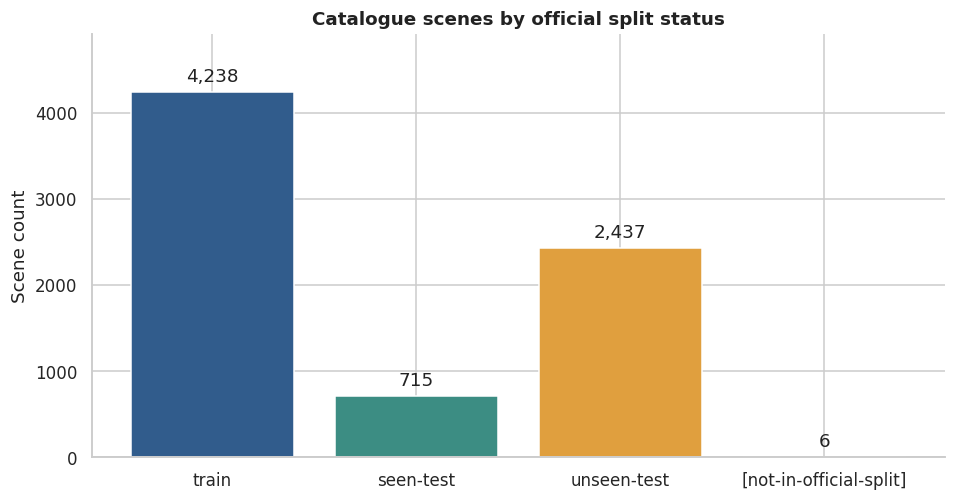

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/split_scene_counts.png')

In [4]:
SPLIT_ORDER = ["train", "seen-test", "unseen-test", "[not-in-official-split]"]


def summarise_toysad_splits(scene_frame: pd.DataFrame) -> pd.DataFrame:
    """Summarise scene, category, asset, object, and availability coverage by split."""
    summary = (
        scene_frame.groupby("split", observed=True)
        .agg(
            scene_count=("scene_id", "size"),
            category_count=("category", "nunique"),
            base_asset_count=("base_asset_id", "nunique"),
            object_count=("object_count", "sum"),
            anomalous_object_count=("anomaly_count", "sum"),
            availability_ready=("availability_ok", "sum"),
        )
        .reindex(SPLIT_ORDER)
        .reset_index()
    )
    summary["scene_percent"] = (100 * summary["scene_count"] / len(scene_frame)).round(2)
    summary["expected_rgb_views"] = summary["scene_count"] * 20
    summary["availability_ready_percent"] = (
        100 * summary["availability_ready"] / summary["scene_count"]
    ).round(2)
    return summary


def paint_split_profile(split_frame: pd.DataFrame) -> Path:
    """Plot catalogue scene counts using stable split colours."""
    figure, axis = plt.subplots(figsize=(10, 5))
    colours = [TOYSAD_COLOURS[name] for name in split_frame["split"]]
    bars = axis.bar(split_frame["split"], split_frame["scene_count"], color=colours)
    axis.bar_label(bars, labels=[f"{value:,}" for value in split_frame["scene_count"]], padding=4)
    axis.set_title("Catalogue scenes by official split status")
    axis.set_xlabel("")
    axis.set_ylabel("Scene count")
    axis.set_ylim(0, split_frame["scene_count"].max() * 1.16)
    sns.despine(ax=axis)
    destination = save_eda_figure(figure, "split_scene_counts.png")
    plt.show()
    plt.close(figure)
    return destination


split_summary = summarise_toysad_splits(scene_table)
display(split_summary)
save_eda_table(split_summary, "split_summary.csv")
paint_split_profile(split_summary)

## 3. Scene and anomaly composition

ToysAD scenes contain three, four, or five peer objects. A scene contains either one or two anomalous objects. Views and augmentations must never be counted as additional scenes.

anomalies_in_scene,objects_in_scene,1,2,all_scenes
0,3,3720,0,3720
1,4,1582,668,2250
2,5,1008,418,1426


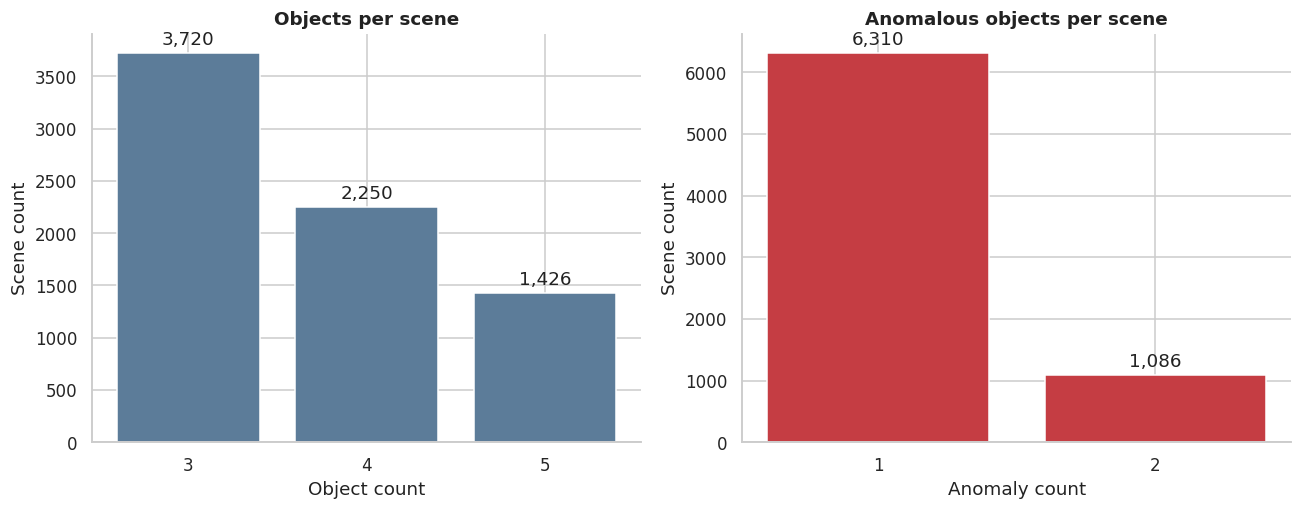

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/scene_structure.png')

In [5]:
def build_scene_structure_matrix(scene_frame: pd.DataFrame) -> pd.DataFrame:
    """Count scenes for each object-count and anomaly-count combination."""
    matrix = pd.crosstab(
        scene_frame["object_count"],
        scene_frame["anomaly_count"],
        rownames=["objects_in_scene"],
        colnames=["anomalies_in_scene"],
    )
    matrix = matrix.reindex(index=[3, 4, 5], columns=[1, 2], fill_value=0)
    matrix["all_scenes"] = matrix.sum(axis=1)
    return matrix.reset_index()


def paint_scene_structure_panels(scene_frame: pd.DataFrame) -> Path:
    """Show object-count and anomaly-count distributions side by side."""
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    object_counts = scene_frame["object_count"].value_counts().sort_index()
    object_bars = axes[0].bar(
        object_counts.index.astype(str),
        object_counts.values,
        color=TOYSAD_COLOURS["normal"],
    )
    axes[0].bar_label(object_bars, labels=[f"{value:,}" for value in object_counts.values], padding=3)
    axes[0].set_title("Objects per scene")
    axes[0].set_xlabel("Object count")
    axes[0].set_ylabel("Scene count")

    anomaly_counts = scene_frame["anomaly_count"].value_counts().sort_index()
    anomaly_bars = axes[1].bar(
        anomaly_counts.index.astype(str),
        anomaly_counts.values,
        color=TOYSAD_COLOURS["anomaly"],
    )
    axes[1].bar_label(anomaly_bars, labels=[f"{value:,}" for value in anomaly_counts.values], padding=3)
    axes[1].set_title("Anomalous objects per scene")
    axes[1].set_xlabel("Anomaly count")
    axes[1].set_ylabel("Scene count")

    for axis in axes:
        sns.despine(ax=axis)

    figure.tight_layout()
    destination = save_eda_figure(figure, "scene_structure.png")
    plt.show()
    plt.close(figure)
    return destination


scene_structure_matrix = build_scene_structure_matrix(scene_table)
display(scene_structure_matrix)
save_eda_table(scene_structure_matrix, "scene_structure_matrix.csv")
paint_scene_structure_panels(scene_table)

## 4. Category coverage

The category table retains all 51 categories. The chart is split-aware so a large overall count cannot hide whether a category occurs only in one protocol split.

,category,scene_count,base_asset_count,object_count,anomalous_object_count,availability_ready,train,seen-test,unseen-test,[not-in-official-split]
4,bottle,596,80,2226,695,594,505,90,0,1
39,mug,529,69,1917,599,529,0,0,529,0
29,hammer,410,53,1520,480,408,395,14,0,1
16,cup,359,46,1300,417,359,0,0,359,0
20,dog,310,41,1154,356,308,263,47,0,0
46,robot,300,38,1130,342,298,0,0,298,2
27,glass,246,32,909,282,244,0,0,245,1
33,key,232,29,877,262,231,0,0,232,0
45,plate,220,28,795,247,220,0,0,220,0
43,penguin,206,28,761,234,205,0,0,205,1


,category,scene_count,base_asset_count,object_count,anomalous_object_count,availability_ready,train,seen-test,unseen-test,[not-in-official-split]
28,hamburger,52,7,193,56,52,44,8,0,0
34,light_bulb,48,7,173,53,48,40,8,0,0
25,frog,43,6,157,46,43,36,7,0,0
40,octopus,42,6,146,45,42,35,7,0,0
26,giraffe,41,5,148,42,41,34,7,0,0
50,train,33,4,122,36,33,0,0,33,0
3,boat,29,4,117,34,29,24,5,0,0
8,bus,24,4,89,24,24,20,4,0,0
9,butterfly,23,3,83,26,23,19,4,0,0
36,lizard,5,1,21,5,5,4,1,0,0


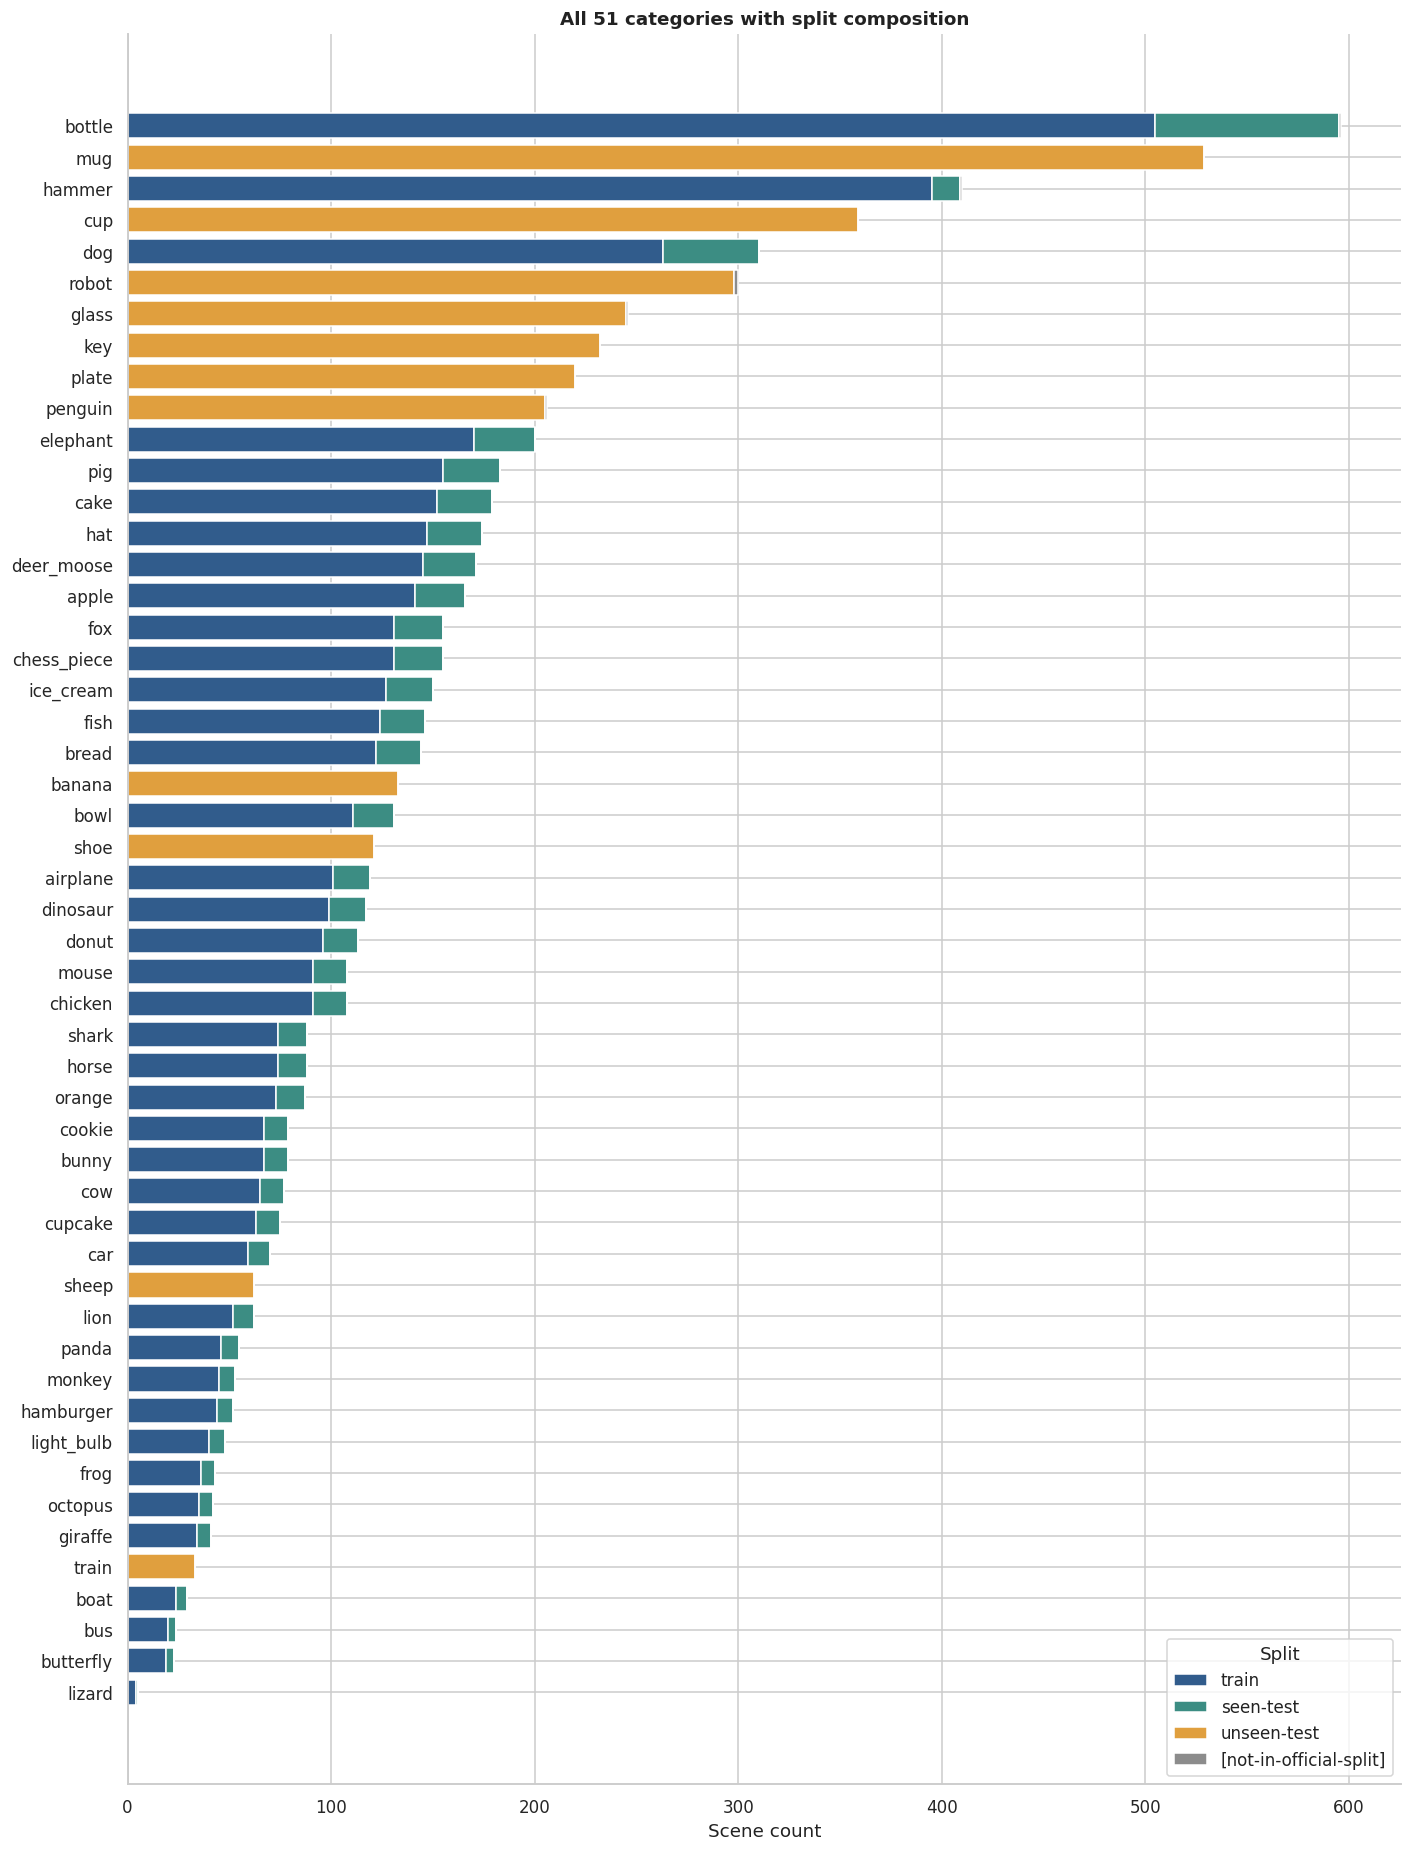

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/category_split_landscape.png')

In [6]:
def build_category_profile(scene_frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Combine overall category statistics with scene counts by split."""
    overall = (
        scene_frame.groupby("category", observed=True)
        .agg(
            scene_count=("scene_id", "size"),
            base_asset_count=("base_asset_id", "nunique"),
            object_count=("object_count", "sum"),
            anomalous_object_count=("anomaly_count", "sum"),
            availability_ready=("availability_ok", "sum"),
        )
    )
    by_split = pd.crosstab(scene_frame["category"], scene_frame["split"])
    by_split = by_split.reindex(columns=SPLIT_ORDER, fill_value=0)
    combined = overall.join(by_split).reset_index()
    combined = combined.sort_values(["scene_count", "category"], ascending=[False, True])
    return combined, by_split.reset_index()


def paint_category_landscape(category_frame: pd.DataFrame) -> Path:
    """Draw all categories as stacked split counts."""
    plotting = category_frame.sort_values(["scene_count", "category"], ascending=[True, True])
    figure, axis = plt.subplots(figsize=(13, 17))
    left = np.zeros(len(plotting))
    for split_name in SPLIT_ORDER:
        values = plotting[split_name].to_numpy()
        axis.barh(
            plotting["category"],
            values,
            left=left,
            label=split_name,
            color=TOYSAD_COLOURS[split_name],
        )
        left += values

    axis.set_title("All 51 categories with split composition")
    axis.set_xlabel("Scene count")
    axis.set_ylabel("")
    axis.legend(title="Split", loc="lower right")
    sns.despine(ax=axis)
    figure.tight_layout()
    destination = save_eda_figure(figure, "category_split_landscape.png")
    plt.show()
    plt.close(figure)
    return destination


category_summary, category_by_split = build_category_profile(scene_table)
display(category_summary.head(15))
display(category_summary.tail(10))
save_eda_table(category_summary, "category_summary.csv")
save_eda_table(category_by_split, "category_by_split.csv")
paint_category_landscape(category_summary)

In [7]:
def build_category_split_coverage(scene_frame: pd.DataFrame) -> pd.DataFrame:
    """Report which category sets are available to each protocol split."""
    rows = []
    for split_name in SPLIT_ORDER:
        categories = sorted(scene_frame.loc[scene_frame["split"] == split_name, "category"].unique())
        rows.append({
            "split": split_name,
            "category_count": len(categories),
            "categories": ", ".join(categories),
        })
    return pd.DataFrame(rows)


category_split_coverage = build_category_split_coverage(scene_table)
display(category_split_coverage)
save_eda_table(category_split_coverage, "category_split_coverage.csv")

,split,category_count,categories
0,train,40,"airplane, apple, boat, bottle, bowl, bread, bu..."
1,seen-test,40,"airplane, apple, boat, bottle, bowl, bread, bu..."
2,unseen-test,11,"banana, cup, glass, key, mug, penguin, plate, ..."
3,[not-in-official-split],5,"bottle, glass, hammer, penguin, robot"


PosixPath('/kaggle/working/toysad8k_full_dataset_eda/category_split_coverage.csv')

## 5. Anomaly families and variants

Family names below are the raw prefixes stored in anomaly asset paths. Counts refer to anomalous objects, not scenes. A two-anomaly scene contributes two anomaly records. The notebook does not invent a semantic lookup table beyond the supplied prefixes.

split,anomaly_family,train,seen-test,unseen-test,[not-in-official-split],all_splits
3,disc,1432,184,550,0,2166
5,miss,878,189,397,3,1467
1,crack,830,192,410,0,1432
4,frac,848,137,431,0,1416
0,bump,431,50,566,3,1050
2,defr,274,38,282,0,594
6,rota,106,25,86,0,217
7,tran,68,8,64,0,140


,anomaly_family,anomaly_variant,anomalous_object_count
16,disc,disc-001,1073
7,crack,crack-001,868
22,frac,frac-001,868
28,miss,miss-001,842
17,disc,disc-002,648
0,bump,bump-001,640
12,defr,defr-001,432
8,crack,crack-002,415
29,miss,miss-002,404
23,frac,frac-002,397


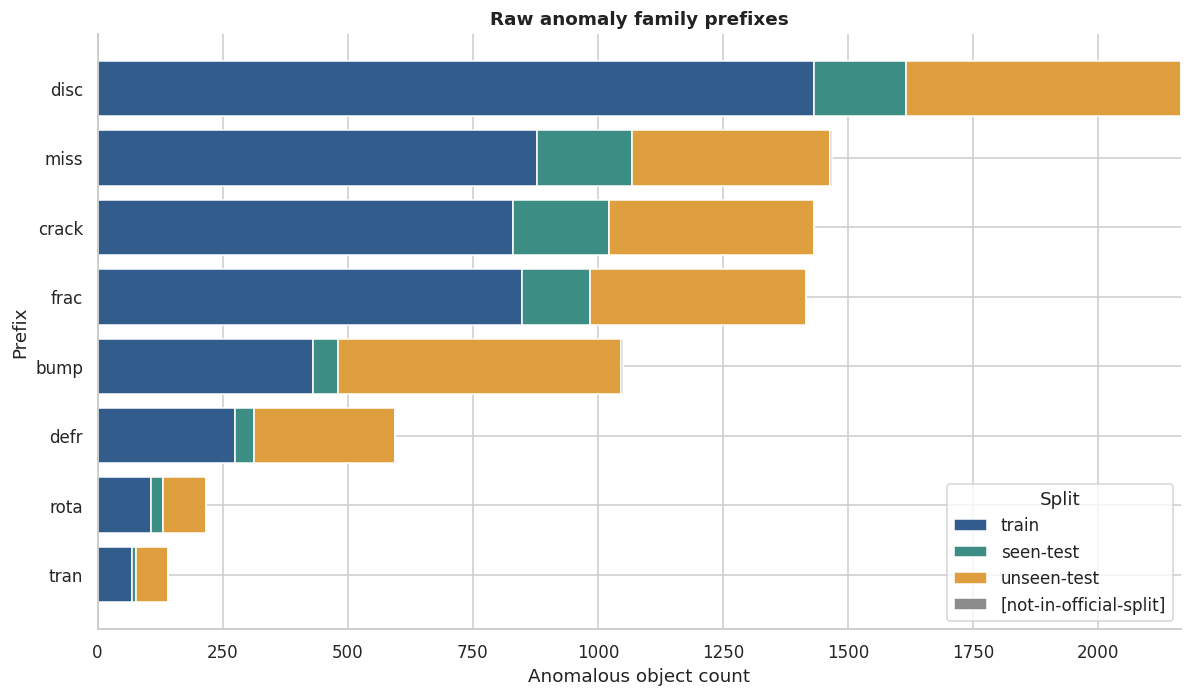

In [8]:
def build_anomaly_family_profile(object_frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Count raw anomaly families and detailed variants across splits."""
    anomalies = object_frame.loc[object_frame["is_anomaly"]].copy()

    family_by_split = pd.crosstab(anomalies["anomaly_family"], anomalies["split"])
    family_by_split = family_by_split.reindex(columns=SPLIT_ORDER, fill_value=0)
    family_by_split["all_splits"] = family_by_split.sum(axis=1)
    family_by_split = (
        family_by_split.reset_index()
        .sort_values(["all_splits", "anomaly_family"], ascending=[False, True])
    )

    variant_summary = (
        anomalies.groupby(["anomaly_family", "anomaly_variant"], observed=True)
        .size()
        .rename("anomalous_object_count")
        .reset_index()
        .sort_values(["anomalous_object_count", "anomaly_variant"], ascending=[False, True])
    )
    return family_by_split, variant_summary


def paint_anomaly_family_profile(family_frame: pd.DataFrame) -> Path:
    """Plot raw anomaly family counts as a split-aware horizontal chart."""
    plotting = family_frame.sort_values("all_splits", ascending=True)
    figure, axis = plt.subplots(figsize=(11, 6.5))
    left = np.zeros(len(plotting))
    for split_name in SPLIT_ORDER:
        values = plotting[split_name].to_numpy()
        axis.barh(
            plotting["anomaly_family"],
            values,
            left=left,
            label=split_name,
            color=TOYSAD_COLOURS[split_name],
        )
        left += values

    axis.set_title("Raw anomaly family prefixes")
    axis.set_xlabel("Anomalous object count")
    axis.set_ylabel("Prefix")
    axis.legend(title="Split", loc="lower right")
    sns.despine(ax=axis)
    figure.tight_layout()
    destination = save_eda_figure(figure, "anomaly_family_counts.png")
    plt.show()
    plt.close(figure)
    return destination


anomaly_family_summary, anomaly_variant_summary = build_anomaly_family_profile(object_table)
display(anomaly_family_summary)
display(anomaly_variant_summary.head(20))
save_eda_table(anomaly_family_summary, "anomaly_family_by_split.csv")
save_eda_table(anomaly_variant_summary, "anomaly_variant_summary.csv")
paint_anomaly_family_profile(anomaly_family_summary)

assert int(anomaly_family_summary["all_splits"].sum()) == int(object_table["is_anomaly"].sum())

## 6. Base assets and leakage controls

A base asset can generate several scene variants. Internal development, calibration, and lock splits must be assigned by base asset. The official seen-test split intentionally measures seen assets, so overlap between train and seen-test is reported rather than treated as a catalogue error.

,category,base_asset_id,scene_count,split_count,splits,warning_scene_count
200,cake,cake_014,17,1,train,0
695,lion,lion_014,17,1,train,0
925,robot,robot_073,17,2,[not-in-official-split]|unseen-test,1
675,key,key_033,16,1,unseen-test,0
929,robot,robot_090,16,1,unseen-test,0
961,shoe,shoe_020,16,1,unseen-test,0
543,hamburger,hamburger_005,15,1,train,0
665,key,key_020,15,1,unseen-test,1
843,pig,pig_002,15,1,train,0
256,chicken,chicken_017,14,1,train,0


,split,train,seen-test,unseen-test,[not-in-official-split]
0,train,578,33,0,2
1,seen-test,33,113,0,0
2,unseen-test,0,0,316,4
3,[not-in-official-split],2,0,4,6


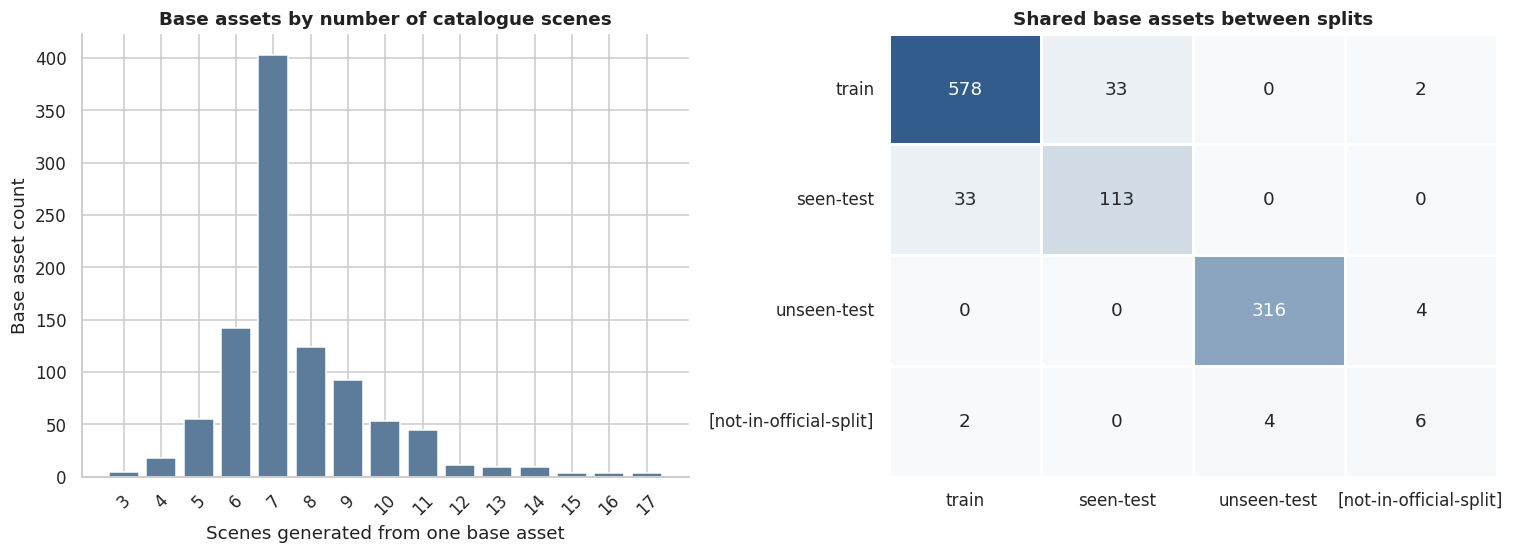

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/base_asset_profile.png')

In [9]:
def build_base_asset_profile(scene_frame: pd.DataFrame) -> pd.DataFrame:
    """Summarise how many scenes and splits are attached to each base asset."""
    return (
        scene_frame.groupby(["category", "base_asset_id"], observed=True)
        .agg(
            scene_count=("scene_id", "size"),
            split_count=("split", "nunique"),
            splits=("split", lambda values: "|".join(sorted(set(values)))),
            warning_scene_count=("availability_ok", lambda values: int((~values).sum())),
        )
        .reset_index()
        .sort_values(["scene_count", "base_asset_id"], ascending=[False, True])
    )


def build_asset_overlap_matrix(scene_frame: pd.DataFrame) -> pd.DataFrame:
    """Count shared base assets for each pair of protocol splits."""
    asset_sets = {
        split_name: set(scene_frame.loc[scene_frame["split"] == split_name, "base_asset_id"])
        for split_name in SPLIT_ORDER
    }
    matrix = pd.DataFrame(0, index=SPLIT_ORDER, columns=SPLIT_ORDER, dtype=int)
    for row_name in SPLIT_ORDER:
        for column_name in SPLIT_ORDER:
            matrix.loc[row_name, column_name] = len(asset_sets[row_name] & asset_sets[column_name])
    matrix.index.name = "split"
    return matrix.reset_index()


def paint_asset_profile(asset_frame: pd.DataFrame, overlap_frame: pd.DataFrame) -> Path:
    """Show scenes per asset and the pairwise split overlap matrix."""
    figure, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    asset_scene_counts = asset_frame["scene_count"].value_counts().sort_index()
    axes[0].bar(
        asset_scene_counts.index.astype(str),
        asset_scene_counts.values,
        color=TOYSAD_COLOURS["normal"],
    )
    axes[0].set_title("Base assets by number of catalogue scenes")
    axes[0].set_xlabel("Scenes generated from one base asset")
    axes[0].set_ylabel("Base asset count")
    axes[0].tick_params(axis="x", rotation=45)
    sns.despine(ax=axes[0])

    overlap_values = overlap_frame.set_index("split").loc[SPLIT_ORDER, SPLIT_ORDER]
    sns.heatmap(
        overlap_values,
        annot=True,
        fmt=",d",
        cmap=LinearSegmentedColormap.from_list("toysad_blue", ["#F7FAFC", "#315C8C"]),
        cbar=False,
        linewidths=0.8,
        linecolor="white",
        ax=axes[1],
    )
    axes[1].set_title("Shared base assets between splits")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("")

    figure.tight_layout()
    destination = save_eda_figure(figure, "base_asset_profile.png")
    plt.show()
    plt.close(figure)
    return destination


base_asset_summary = build_base_asset_profile(scene_table)
base_asset_scene_distribution = (
    base_asset_summary["scene_count"]
    .value_counts()
    .sort_index()
    .rename_axis("scenes_per_base_asset")
    .rename("base_asset_count")
    .reset_index()
)
base_asset_overlap = build_asset_overlap_matrix(scene_table)

display(base_asset_summary.head(15))
display(base_asset_overlap)
save_eda_table(base_asset_summary, "base_asset_summary.csv")
save_eda_table(base_asset_scene_distribution, "base_asset_scene_count_distribution.csv")
save_eda_table(base_asset_overlap, "base_asset_overlap.csv")
paint_asset_profile(base_asset_summary, base_asset_overlap)

## 7. Availability and data quality

Quality findings are shown as aggregate counts for all splits. Scene identifiers are exported only for training issues because those records affect the train-derived eligible pool. Official test issue identifiers are not displayed or exported by this notebook.

,measure,value
0,availability-ready scenes,7373
1,scenes with one or more warnings,23
2,warning records,24


split,issue,train,seen-test,unseen-test,[not-in-official-split],all_splits
0,object_segmentation_count_above_expected,8,0,3,0,11
1,object_segmentation_count_below_expected,6,0,2,0,8
2,rgb_view_count_mismatches,0,0,0,4,4
3,scene_mask_count_mismatches,1,0,0,0,1


,scene_id,split,issue
0,bottle_010-006,train,object_segmentation_count_above_expected
1,bottle_029-006,train,object_segmentation_count_above_expected
2,bowl_004-007,train,object_segmentation_count_above_expected
3,cake_010-005,train,object_segmentation_count_above_expected
4,deer_moose_042-007,train,object_segmentation_count_above_expected
5,hammer_047-007,train,object_segmentation_count_above_expected
6,horse_018-002,train,object_segmentation_count_above_expected
7,horse_025-006,train,object_segmentation_count_above_expected
8,apple_001-009,train,object_segmentation_count_below_expected
9,bowl_002-005,train,object_segmentation_count_below_expected


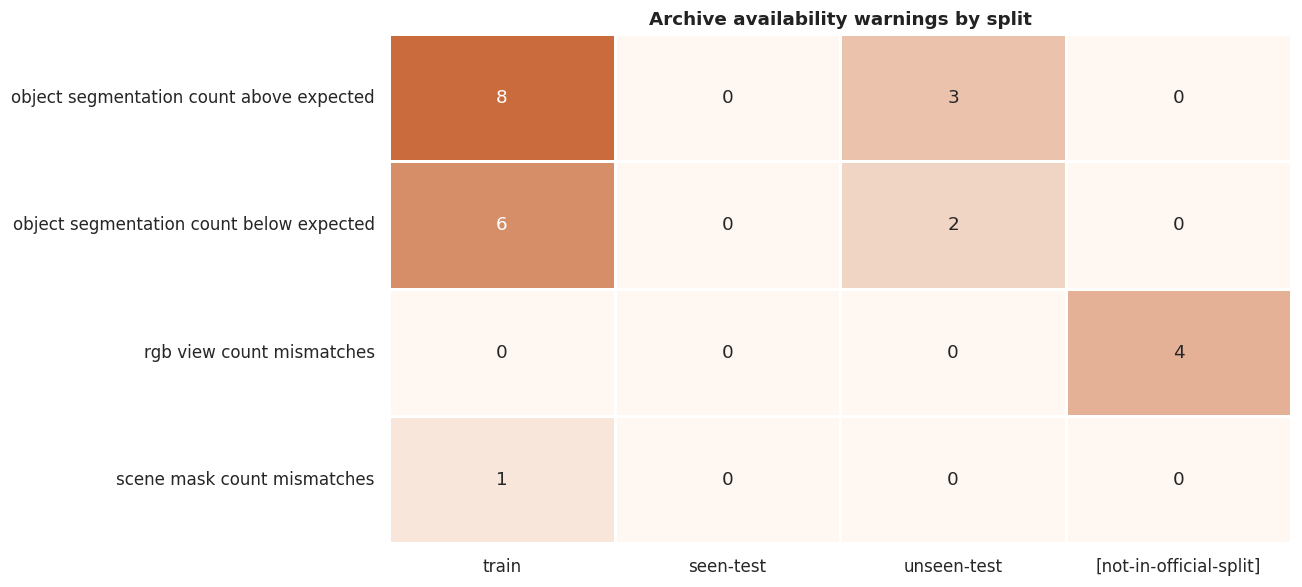

In [10]:
def build_quality_issue_table(scene_records: list[dict]) -> pd.DataFrame:
    """Expand per-scene warnings into one row per issue."""
    rows = []
    for scene in scene_records:
        split_name = scene["split"] or "[not-in-official-split]"
        for warning in scene.get("availability_warnings", []):
            rows.append({
                "scene_id": scene["scene_id"],
                "split": split_name,
                "issue": warning,
            })
    return pd.DataFrame(rows)


def paint_quality_profile(issue_by_split_frame: pd.DataFrame) -> Path:
    """Plot aggregate issue counts without exposing official test scene identities."""
    plotting = issue_by_split_frame.set_index("issue").reindex(columns=SPLIT_ORDER, fill_value=0)
    plotting.index = [label.replace("_", " ") for label in plotting.index]

    figure, axis = plt.subplots(figsize=(12, 5.5))
    sns.heatmap(
        plotting,
        annot=True,
        fmt=",d",
        cmap=LinearSegmentedColormap.from_list("toysad_quality", ["#FFF8F2", "#C96B3C"]),
        cbar=False,
        linewidths=0.8,
        linecolor="white",
        ax=axis,
    )
    axis.set_title("Archive availability warnings by split")
    axis.set_xlabel("")
    axis.set_ylabel("")
    figure.tight_layout()
    destination = save_eda_figure(figure, "availability_warnings.png")
    plt.show()
    plt.close(figure)
    return destination


quality_issues = build_quality_issue_table(master_catalogue["scenes"])
quality_issue_by_split = pd.crosstab(quality_issues["issue"], quality_issues["split"])
quality_issue_by_split = quality_issue_by_split.reindex(columns=SPLIT_ORDER, fill_value=0)
quality_issue_by_split["all_splits"] = quality_issue_by_split.sum(axis=1)
quality_issue_by_split = quality_issue_by_split.reset_index()

quality_overview = pd.DataFrame([
    {"measure": "availability-ready scenes", "value": int(scene_table["availability_ok"].sum())},
    {"measure": "scenes with one or more warnings", "value": int((~scene_table["availability_ok"]).sum())},
    {"measure": "warning records", "value": len(quality_issues)},
])
training_quality_issues = (
    quality_issues.loc[quality_issues["split"] == "train"]
    .sort_values(["issue", "scene_id"])
    .reset_index(drop=True)
)

display(quality_overview)
display(quality_issue_by_split)
display(training_quality_issues)
save_eda_table(quality_overview, "availability_overview.csv")
save_eda_table(quality_issue_by_split, "availability_issue_by_split.csv")
save_eda_table(training_quality_issues, "training_quality_issues.csv")
paint_quality_profile(quality_issue_by_split)

assert int((~scene_table["availability_ok"]).sum()) == 23
assert len(quality_issues) == 24

## 8. Full archive file and modality inventory

This section queries every indexed archive member without extracting the archive. Object segmentation counts include named object masks and floor masks. The archive also contains scene3d-only records, so archive-wide file totals are not expected to equal simple multiples of the 7,396 scene2d catalogue.

,component,file_count,compressed_bytes,uncompressed_bytes,compressed_gib,uncompressed_gib
0,object masks,546869,17096892965,18720786565,15.923,17.435
1,depth EXR,148283,11754294470,11924243032,10.947,11.105
2,floor masks,148145,4821330127,5053486671,4.490,4.706
3,RGB,148139,18757267213,18754089615,17.469,17.466
4,scene masks,147980,195776542,196687781,0.182,0.183
5,scene3d metadata,7400,29864250,181112561,0.028,0.169
6,scene2d metadata,7396,2979909,16531033,0.003,0.015
7,scene3d metadatav2,7392,30407279,183271274,0.028,0.171


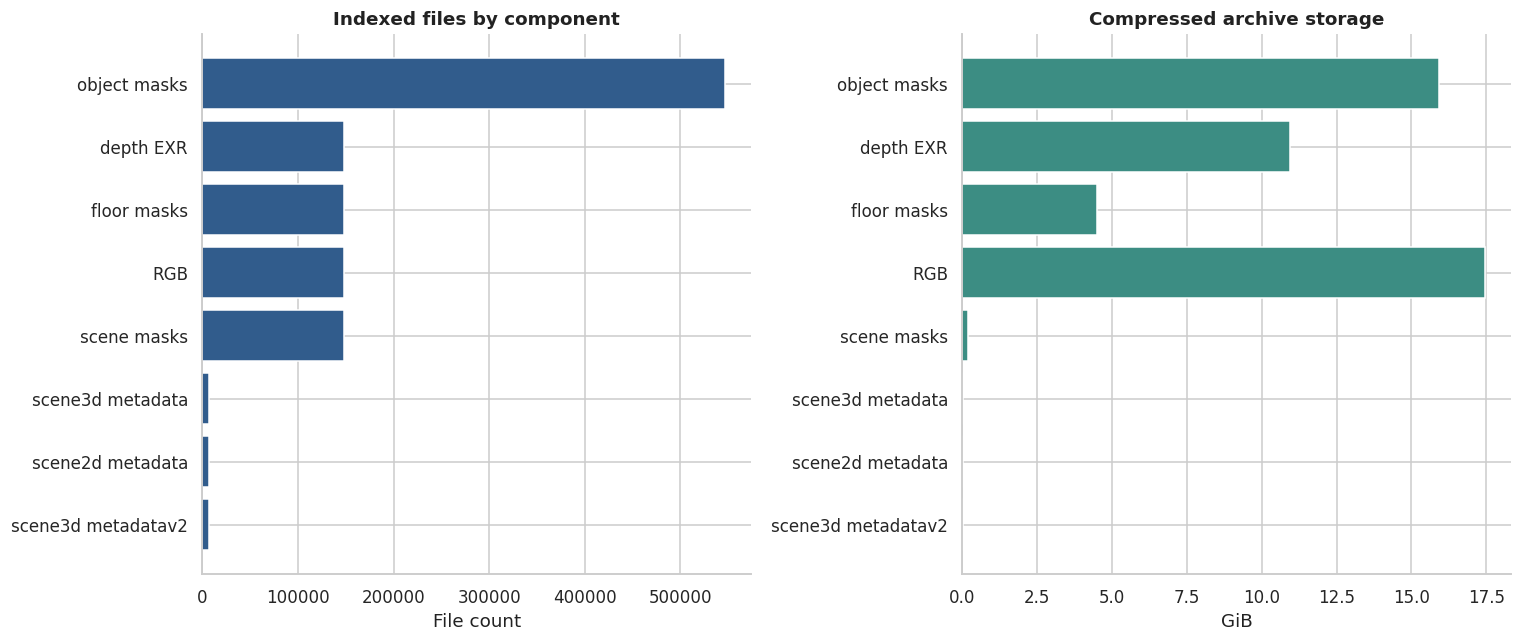

Indexed non-directory files: 1,161,604
Compressed archive total: 49.070 GiB
Uncompressed archive total: 51.250 GiB


In [11]:
def query_archive_modality_inventory(index_path: Path) -> pd.DataFrame:
    """Classify every non-directory archive member using its indexed path."""
    query = """
        SELECT
            CASE
                WHEN name LIKE '%/segmentations/floor_object/%' THEN 'floor masks'
                WHEN name LIKE '%/segmentations/%' THEN 'object masks'
                WHEN name LIKE '%/RGB/%' THEN 'RGB'
                WHEN name LIKE '%/masks/%' THEN 'scene masks'
                WHEN name LIKE '%/depth_exr/%' THEN 'depth EXR'
                WHEN name LIKE '%/scene2d.metadata.json' THEN 'scene2d metadata'
                WHEN name LIKE '%/scene3d.metadata.json' THEN 'scene3d metadata'
                WHEN name LIKE '%/scene3d.metadatav2.json' THEN 'scene3d metadatav2'
                ELSE 'unclassified'
            END AS component,
            COUNT(*) AS file_count,
            SUM(compressed_size) AS compressed_bytes,
            SUM(uncompressed_size) AS uncompressed_bytes
        FROM members
        WHERE is_directory = 0
        GROUP BY component
        ORDER BY file_count DESC
    """
    with sqlite3.connect(f"file:{index_path}?mode=ro", uri=True) as connection:
        inventory = pd.read_sql_query(query, connection)
    inventory["compressed_gib"] = (inventory["compressed_bytes"] / 1024**3).round(3)
    inventory["uncompressed_gib"] = (inventory["uncompressed_bytes"] / 1024**3).round(3)
    return inventory


def paint_archive_inventory(inventory_frame: pd.DataFrame) -> Path:
    """Compare archive file counts and compressed storage by component."""
    plotting = inventory_frame.sort_values("file_count", ascending=True)
    figure, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].barh(plotting["component"], plotting["file_count"], color="#315C8C")
    axes[0].set_title("Indexed files by component")
    axes[0].set_xlabel("File count")
    axes[0].set_ylabel("")
    axes[0].ticklabel_format(style="plain", axis="x")
    sns.despine(ax=axes[0])

    axes[1].barh(plotting["component"], plotting["compressed_gib"], color="#3C8D83")
    axes[1].set_title("Compressed archive storage")
    axes[1].set_xlabel("GiB")
    axes[1].set_ylabel("")
    sns.despine(ax=axes[1])

    figure.tight_layout()
    destination = save_eda_figure(figure, "archive_modality_inventory.png")
    plt.show()
    plt.close(figure)
    return destination


archive_modality_inventory = query_archive_modality_inventory(ARCHIVE_INDEX_SOURCE)
display(archive_modality_inventory)
save_eda_table(archive_modality_inventory, "archive_modality_inventory.csv")
paint_archive_inventory(archive_modality_inventory)

print(f"Indexed non-directory files: {archive_modality_inventory['file_count'].sum():,}")
print(f"Compressed archive total: {archive_modality_inventory['compressed_gib'].sum():.3f} GiB")
print(f"Uncompressed archive total: {archive_modality_inventory['uncompressed_gib'].sum():.3f} GiB")

## 9. Complete archive image header validation

This section opens every indexed PNG and EXR header from the active source storage. Locally that is the validated ZIP; on Kaggle it is the read-only unpacked dataset mount. The package manifest already records a successful full CRC validation, so this pass focuses on file signatures, structure, and image dimensions.

In [12]:
PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"
OPENEXR_SIGNATURE = b"\x76\x2f\x31\x01"
PNG_COLOUR_MODES = {
    0: "grayscale",
    2: "RGB",
    3: "indexed",
    4: "grayscale with alpha",
    6: "RGBA",
}


LOCAL_FILE_HEADER = struct.Struct("<4s5H3I2H")


class IndexedToysArchive:
    """Read ZIP members by indexed offsets without loading the full central directory."""

    def __init__(self, archive_path: Path, index_path: Path) -> None:
        self._archive_handle = archive_path.open("rb")
        self._database = sqlite3.connect(f"file:{index_path}?mode=ro", uri=True)
        self._database.row_factory = sqlite3.Row

    def iter_image_records(self):
        """Yield all PNG and EXR index rows in archive order."""
        query = """
            SELECT name, compressed_size, uncompressed_size, crc32,
                   compression_method, flags, local_header_offset
            FROM members
            WHERE is_directory = 0 AND extension IN ('.png', '.exr')
            ORDER BY id
        """
        yield from self._database.execute(query)

    def find_member(self, member_name: str):
        """Return the indexed record for one exact archive member."""
        query = """
            SELECT name, compressed_size, uncompressed_size, crc32,
                   compression_method, flags, local_header_offset
            FROM members
            WHERE name = ? AND is_directory = 0
        """
        record = self._database.execute(query, (member_name,)).fetchone()
        if record is None:
            raise KeyError(f"Archive member not found: {member_name}")
        return record

    def member_data_offset(self, record) -> int:
        """Resolve the compressed payload offset from a local ZIP header."""
        self._archive_handle.seek(record["local_header_offset"])
        header = self._archive_handle.read(LOCAL_FILE_HEADER.size)
        if len(header) != LOCAL_FILE_HEADER.size:
            raise ValueError(f"Incomplete local ZIP header: {record['name']}")
        fields = LOCAL_FILE_HEADER.unpack(header)
        signature = fields[0]
        name_length = fields[-2]
        extra_length = fields[-1]
        if signature != b"PK\x03\x04":
            raise ValueError(f"Invalid local ZIP signature: {record['name']}")
        if record["flags"] & 1:
            raise ValueError(f"Encrypted member is unsupported: {record['name']}")
        return record["local_header_offset"] + LOCAL_FILE_HEADER.size + name_length + extra_length

    def read_record_prefix(self, record, output_limit: int) -> bytes:
        """Read a decompressed member prefix using indexed sizes and offsets."""
        self._archive_handle.seek(self.member_data_offset(record))
        target_size = min(output_limit, record["uncompressed_size"])

        if record["compression_method"] == 0:
            return self._archive_handle.read(target_size)
        if record["compression_method"] != 8:
            raise ValueError(
                f"Unsupported compression method {record['compression_method']}: {record['name']}"
            )

        decoder = zlib.decompressobj(-zlib.MAX_WBITS)
        output = bytearray()
        compressed_remaining = record["compressed_size"]
        while compressed_remaining > 0 and len(output) < target_size:
            chunk = self._archive_handle.read(min(16384, compressed_remaining))
            if not chunk:
                break
            compressed_remaining -= len(chunk)
            pending = chunk
            while pending and len(output) < target_size:
                output.extend(decoder.decompress(pending, target_size - len(output)))
                pending = decoder.unconsumed_tail
        return bytes(output)

    def read_member(self, member_name: str) -> bytes:
        """Read and CRC-check one complete member by name."""
        record = self.find_member(member_name)
        payload = self.read_record_prefix(record, record["uncompressed_size"])
        if len(payload) != record["uncompressed_size"]:
            raise ValueError(f"Incomplete member payload: {member_name}")
        if (zlib.crc32(payload) & 0xFFFFFFFF) != (record["crc32"] & 0xFFFFFFFF):
            raise ValueError(f"CRC mismatch: {member_name}")
        return payload

    def close(self) -> None:
        """Close the archive handle and read-only index connection."""
        self._archive_handle.close()
        self._database.close()


class ExtractedToysArchive:
    """Read Kaggle's unpacked members using the same verified archive index."""

    def __init__(self, archive_root: Path, index_path: Path) -> None:
        self._archive_root = archive_root
        self._database = sqlite3.connect(f"file:{index_path}?mode=ro", uri=True)
        self._database.row_factory = sqlite3.Row

    def iter_image_records(self):
        """Yield all PNG and EXR index rows in archive order."""
        query = """
            SELECT name, compressed_size, uncompressed_size, crc32,
                   compression_method, flags, local_header_offset
            FROM members
            WHERE is_directory = 0 AND extension IN ('.png', '.exr')
            ORDER BY id
        """
        yield from self._database.execute(query)

    def find_member(self, member_name: str):
        """Return the indexed record for one exact unpacked member."""
        query = """
            SELECT name, compressed_size, uncompressed_size, crc32,
                   compression_method, flags, local_header_offset
            FROM members
            WHERE name = ? AND is_directory = 0
        """
        record = self._database.execute(query, (member_name,)).fetchone()
        if record is None:
            raise KeyError(f"Archive member not found: {member_name}")
        return record

    def member_path(self, record) -> Path:
        """Map an indexed member name to its read-only Kaggle path."""
        return self._archive_root / record["name"]

    def read_record_prefix(self, record, output_limit: int) -> bytes:
        """Read one unpacked member prefix without loading the full file."""
        with self.member_path(record).open("rb") as handle:
            return handle.read(min(output_limit, record["uncompressed_size"]))

    def read_member(self, member_name: str) -> bytes:
        """Read and CRC-check one complete unpacked member by name."""
        record = self.find_member(member_name)
        payload = self.member_path(record).read_bytes()
        if len(payload) != record["uncompressed_size"]:
            raise ValueError(f"Unpacked member size mismatch: {member_name}")
        if (zlib.crc32(payload) & 0xFFFFFFFF) != (record["crc32"] & 0xFFFFFFFF):
            raise ValueError(f"CRC mismatch: {member_name}")
        return payload

    def close(self) -> None:
        """Close the read-only index connection."""
        self._database.close()


def open_complete_toysad_archive():
    """Open the correct constant-memory reader for local or Kaggle storage."""
    global ARCHIVE_READER
    if ARCHIVE_READER is None:
        if ARCHIVE_ZIP_SOURCE is not None:
            ARCHIVE_READER = IndexedToysArchive(ARCHIVE_ZIP_SOURCE, ARCHIVE_INDEX_SOURCE)
        else:
            ARCHIVE_READER = ExtractedToysArchive(EXTRACTED_ARCHIVE_ROOT, ARCHIVE_INDEX_SOURCE)
    return ARCHIVE_READER


def classify_complete_archive_member(member_name: str) -> str:
    """Map one full-archive path to its raw visual component."""
    if "/segmentations/floor_object/" in member_name:
        return "floor mask"
    if "/segmentations/" in member_name:
        return "object mask"
    if "/RGB/" in member_name:
        return "RGB"
    if "/masks/" in member_name:
        return "scene mask"
    if "/depth_exr/" in member_name:
        return "depth EXR"
    return "unclassified"


def parse_png_identity(header: bytes) -> tuple[int, int, int, str]:
    """Read the PNG signature and IHDR values from 29 bytes."""
    if len(header) < 29 or header[:8] != PNG_SIGNATURE or header[12:16] != b"IHDR":
        raise ValueError("Invalid PNG signature or IHDR header.")
    width, height, bit_depth, colour_type = struct.unpack(">IIBB", header[16:26])
    return width, height, bit_depth, PNG_COLOUR_MODES.get(colour_type, f"colour type {colour_type}")


def read_null_terminated_field(payload: bytes, offset: int) -> tuple[str, int]:
    """Read one null-terminated OpenEXR header field."""
    end = payload.find(b"\x00", offset)
    if end < 0:
        raise ValueError("OpenEXR header field is incomplete.")
    return payload[offset:end].decode("ascii"), end + 1


def parse_openexr_identity(header: bytes) -> tuple[int, int, int, str]:
    """Read the OpenEXR signature, version, and data window."""
    if len(header) < 8 or header[:4] != OPENEXR_SIGNATURE:
        raise ValueError("Invalid OpenEXR signature.")
    version_word = int.from_bytes(header[4:8], byteorder="little")
    offset = 8
    width = None
    height = None

    while offset < len(header) and header[offset] != 0:
        attribute_name, offset = read_null_terminated_field(header, offset)
        _, offset = read_null_terminated_field(header, offset)
        if offset + 4 > len(header):
            raise ValueError("OpenEXR attribute size is incomplete.")
        value_size = int.from_bytes(header[offset:offset + 4], byteorder="little")
        offset += 4
        value = header[offset:offset + value_size]
        if len(value) != value_size:
            raise ValueError("OpenEXR attribute value is incomplete.")
        if attribute_name == "dataWindow" and value_size >= 16:
            x_min, y_min, x_max, y_max = struct.unpack("<iiii", value[:16])
            width = x_max - x_min + 1
            height = y_max - y_min + 1
        offset += value_size

    if width is None or height is None:
        raise ValueError("OpenEXR dataWindow was not found.")
    return width, height, 0, f"OpenEXR version {version_word & 255}"


def inspect_complete_archive_image_headers() -> tuple[pd.DataFrame, pd.DataFrame, float]:
    """Validate every indexed PNG and EXR header from the active source storage."""
    archive = open_complete_toysad_archive()
    profile_counts = Counter()
    failures = []
    scanned_count = 0
    started = perf_counter()

    for member in archive.iter_image_records():
        lower_name = member["name"].lower()
        scanned_count += 1
        try:
            if member["uncompressed_size"] == 0:
                raise ValueError("Zero-byte image member.")
            if lower_name.endswith(".png"):
                header = archive.read_record_prefix(member, 29)
                width, height, bit_depth, encoding = parse_png_identity(header)
                file_type = "PNG"
            else:
                header = archive.read_record_prefix(member, 8192)
                width, height, bit_depth, encoding = parse_openexr_identity(header)
                file_type = "EXR"
            key = (
                classify_complete_archive_member(member["name"]),
                file_type,
                width,
                height,
                bit_depth,
                encoding,
            )
            profile_counts[key] += 1
        except Exception as error:
            scene_id = member["name"].split("/")[1]
            catalogue_scene = scene_lookup.get(scene_id)
            if catalogue_scene is None:
                split_name = "[not-in-scene2d-catalogue]"
            else:
                split_name = catalogue_scene["split"] or "[not-in-official-split]"
            failures.append({
                "member": member["name"],
                "scene_id": scene_id,
                "split": split_name,
                "component": classify_complete_archive_member(member["name"]),
                "error": str(error),
            })

        if scanned_count % 250000 == 0:
            print(f"Checked {scanned_count:,} raw image headers")

    profile_rows = [
        {
            "component": key[0],
            "file_type": key[1],
            "width": key[2],
            "height": key[3],
            "bit_depth": key[4],
            "encoding": key[5],
            "file_count": count,
        }
        for key, count in profile_counts.items()
    ]
    profile = pd.DataFrame(profile_rows).sort_values(["component", "file_type", "encoding"])
    failure_table = pd.DataFrame(
        failures,
        columns=["member", "scene_id", "split", "component", "error"],
    )
    return profile.reset_index(drop=True), failure_table, perf_counter() - started


full_image_header_profile, full_image_header_failures, header_scan_seconds = (
    inspect_complete_archive_image_headers()
)
expected_raw_image_files = int(
    archive_modality_inventory.loc[
        archive_modality_inventory["component"].isin(
            ["RGB", "scene masks", "object masks", "floor masks", "depth EXR"]
        ),
        "file_count",
    ].sum()
)

with sqlite3.connect(f"file:{ARCHIVE_INDEX_SOURCE}?mode=ro", uri=True) as connection:
    expected_zero_byte_images = connection.execute(
        "SELECT COUNT(*) FROM members WHERE is_directory = 0 "
        "AND extension IN ('.png', '.exr') AND uncompressed_size = 0"
    ).fetchone()[0]

assert int(full_image_header_profile["file_count"].sum()) + len(full_image_header_failures) == expected_raw_image_files
assert len(full_image_header_failures) == expected_zero_byte_images
assert set(full_image_header_failures["error"]) == {"Zero-byte image member."}
assert set(full_image_header_profile["width"]) == {256}
assert set(full_image_header_profile["height"]) == {256}

full_image_header_failure_summary = (
    full_image_header_failures.groupby(["split", "component", "error"], observed=True)
    .size()
    .rename("file_count")
    .reset_index()
)

display(full_image_header_profile)
display(full_image_header_failure_summary)
display(full_image_header_failures)
save_eda_table(full_image_header_profile, "full_archive_image_header_profile.csv")
save_eda_table(full_image_header_failures, "full_archive_image_header_failures.csv")
save_eda_table(full_image_header_failure_summary, "full_archive_image_header_failure_summary.csv")
print(f"Checked {expected_raw_image_files:,} complete-archive image headers in {header_scan_seconds:.1f} seconds.")
print(f"Non-empty images are 256 x 256; {len(full_image_header_failures):,} indexed image files are zero bytes.")

Checked 250,000 raw image headers
Checked 500,000 raw image headers
Checked 750,000 raw image headers
Checked 1,000,000 raw image headers


,component,file_type,width,height,bit_depth,encoding,file_count
0,RGB,PNG,256,256,8,RGBA,148136
1,depth EXR,EXR,256,256,0,OpenEXR version 2,148283
2,floor mask,PNG,256,256,8,RGBA,148145
3,object mask,PNG,256,256,8,RGBA,546861
4,scene mask,PNG,256,256,8,grayscale,147980


,split,component,error,file_count
0,[not-in-official-split],RGB,Zero-byte image member.,3
1,[not-in-scene2d-catalogue],object mask,Zero-byte image member.,8


,member,scene_id,split,component,error
0,toysad8k/bread_037-007/segmentations/object.00...,bread_037-007,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
1,toysad8k/hammer_083-003/RGB/0016.png,hammer_083-003,[not-in-official-split],RGB,Zero-byte image member.
2,toysad8k/fox_025-006/segmentations/object.004/...,fox_025-006,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
3,toysad8k/bottle_091-009/segmentations/object/o...,bottle_091-009,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
4,toysad8k/mug_018-005/segmentations/object.003/...,mug_018-005,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
5,toysad8k/apple_048-007/segmentations/object.00...,apple_048-007,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
6,toysad8k/robot_042-001/RGB/0008.png,robot_042-001,[not-in-official-split],RGB,Zero-byte image member.
7,toysad8k/bottle_060-002/segmentations/object/o...,bottle_060-002,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
8,toysad8k/glass_010-001/segmentations/object/ob...,glass_010-001,[not-in-scene2d-catalogue],object mask,Zero-byte image member.
9,toysad8k/mug_009-004/segmentations/object.002/...,mug_009-004,[not-in-scene2d-catalogue],object mask,Zero-byte image member.


Checked 1,139,416 complete-archive image headers in 11738.2 seconds.
Non-empty images are 256 x 256; 11 indexed image files are zero bytes.


## 10. Representative visual inspection from the complete archive

The figures below are read directly from the complete ZIP. Training scenes are used for illustration so official test pixels remain closed to model-development decisions. Red tint identifies the supplied ground-truth anomalous object mask. It is not a SAM output and it is not a defect-region annotation.

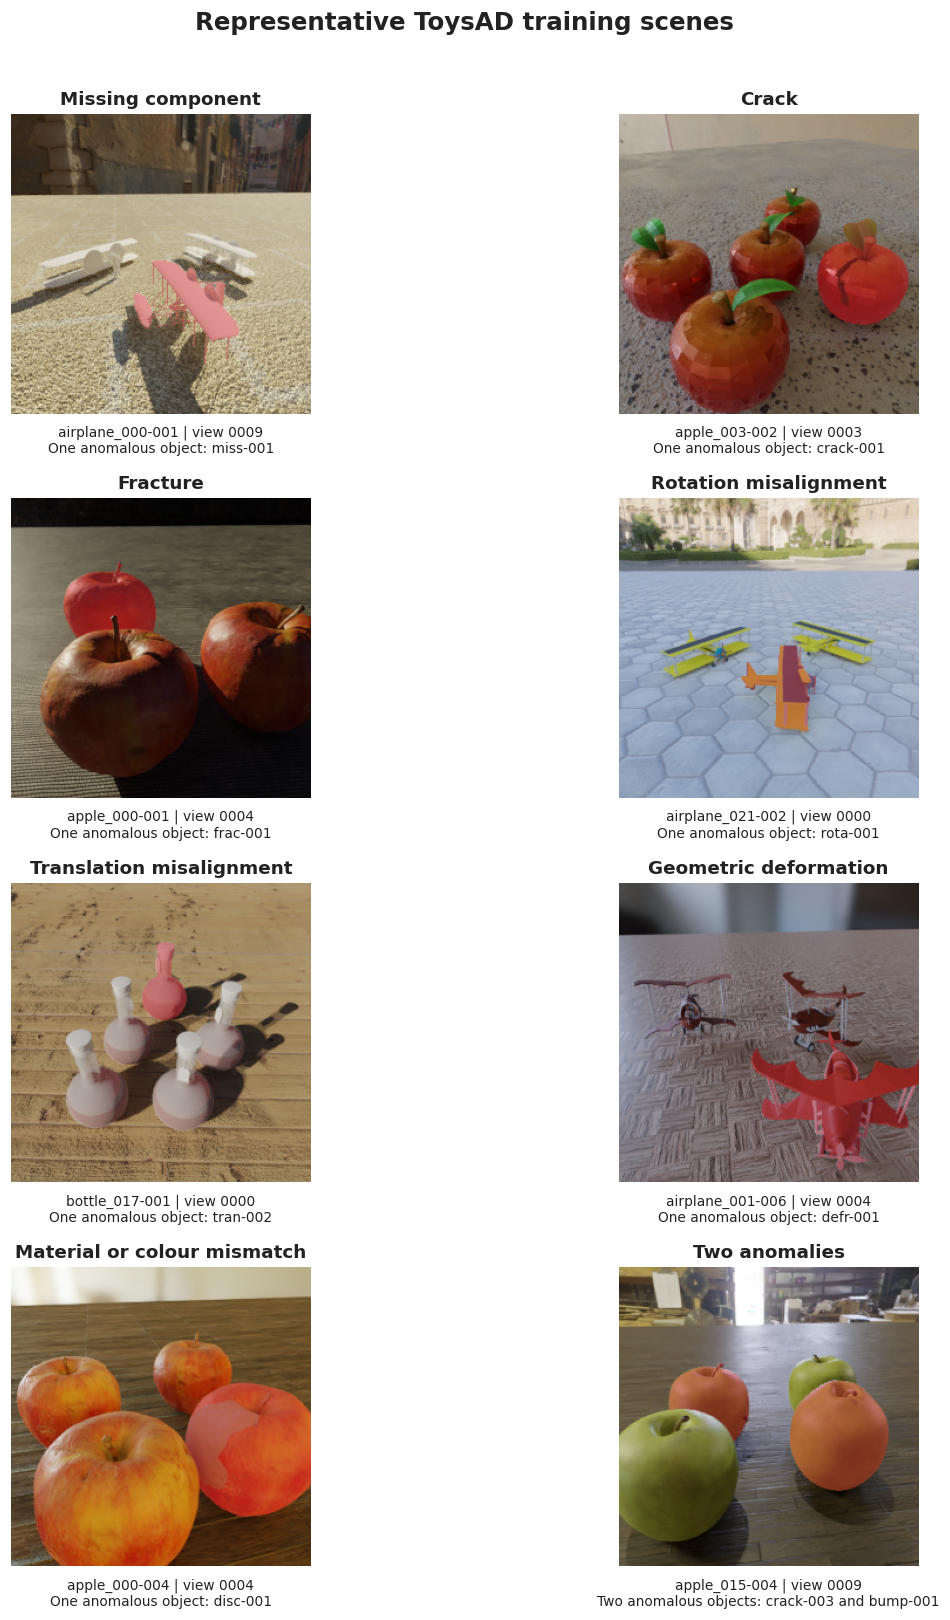

,order,scene_id,view_id,heading,ground_truth
0,1,airplane_000-001,0009,Missing component,One anomalous object: miss-001
1,2,apple_003-002,0003,Crack,One anomalous object: crack-001
2,3,apple_000-001,0004,Fracture,One anomalous object: frac-001
3,4,airplane_021-002,0000,Rotation misalignment,One anomalous object: rota-001
4,5,bottle_017-001,0000,Translation misalignment,One anomalous object: tran-002
5,6,airplane_001-006,0004,Geometric deformation,One anomalous object: defr-001
6,7,apple_000-004,0004,Material or colour mismatch,One anomalous object: disc-001
7,8,apple_015-004,0009,Two anomalies,Two anomalous objects: crack-003 and bump-001


PosixPath('/kaggle/working/toysad8k_full_dataset_eda/visual_example_manifest.csv')

In [13]:
QUALITATIVE_EXAMPLES = [
    {
        "order": 1,
        "scene_id": "airplane_000-001",
        "view_id": "0009",
        "heading": "Missing component",
        "ground_truth": "One anomalous object: miss-001",
        "challenge": "Separate missing geometry from normal viewpoint and size variation.",
    },
    {
        "order": 2,
        "scene_id": "apple_003-002",
        "view_id": "0003",
        "heading": "Crack",
        "ground_truth": "One anomalous object: crack-001",
        "challenge": "The local crack changes contrast under different lighting and poses.",
    },
    {
        "order": 3,
        "scene_id": "apple_000-001",
        "view_id": "0004",
        "heading": "Fracture",
        "ground_truth": "One anomalous object: frac-001",
        "challenge": "Self-occlusion can make the same missing region less visible in other views.",
    },
    {
        "order": 4,
        "scene_id": "airplane_021-002",
        "view_id": "0000",
        "heading": "Rotation misalignment",
        "ground_truth": "One anomalous object: rota-001",
        "challenge": "The orientation is abnormal only relative to the peer arrangement.",
    },
    {
        "order": 5,
        "scene_id": "bottle_017-001",
        "view_id": "0000",
        "heading": "Translation misalignment",
        "ground_truth": "One anomalous object: tran-002",
        "challenge": "The useful signal is peer-relative placement rather than appearance.",
    },
    {
        "order": 6,
        "scene_id": "airplane_001-006",
        "view_id": "0004",
        "heading": "Geometric deformation",
        "ground_truth": "One anomalous object: defr-001",
        "challenge": "Pose differences between peers can resemble silhouette deformation.",
    },
    {
        "order": 7,
        "scene_id": "apple_000-004",
        "view_id": "0004",
        "heading": "Material or colour mismatch",
        "ground_truth": "One anomalous object: disc-001",
        "challenge": "The pale region must be separated from highlights and lighting changes.",
    },
    {
        "order": 8,
        "scene_id": "apple_015-004",
        "view_id": "0009",
        "heading": "Two anomalies",
        "ground_truth": "Two anomalous objects: crack-003 and bump-001",
        "challenge": "Two abnormal peers can contaminate the reference in different ways.",
    },
]


def read_complete_member(member_name: str) -> bytes:
    """Read one named member from the active validated source storage."""
    return open_complete_toysad_archive().read_member(member_name)


def read_complete_json(member_name: str) -> dict:
    """Decode one JSON member from the active validated source storage."""
    return json.loads(read_complete_member(member_name).decode("utf-8"))


def read_complete_image(member_name: str, mode: str) -> np.ndarray:
    """Decode one image member from the active source into a NumPy array."""
    with PillowImage.open(BytesIO(read_complete_member(member_name))) as image:
        return np.asarray(image.convert(mode))


def read_object_mask(member_name: str) -> np.ndarray:
    """Convert one full-archive object segmentation into a Boolean mask."""
    grayscale = read_complete_image(member_name, mode="L")
    return grayscale > 100


def build_anomaly_mask(scene_id: str, view_id: str) -> np.ndarray:
    """Combine supplied whole-object masks for all anomalous objects in one view."""
    scene_root = f"toysad8k/{scene_id}"
    scene3d = read_complete_json(f"{scene_root}/scene3d.metadata.json")
    anomaly_indices = scene_lookup[scene_id]["anomaly_object_indices"]
    combined = np.zeros((256, 256), dtype=bool)

    for object_index in anomaly_indices:
        object_name = scene3d["objects"][object_index]["name"]
        mask_member = (
            f"{scene_root}/segmentations/{object_name}/{object_name}_{view_id}.png"
        )
        combined |= read_object_mask(mask_member)
    return combined


def tint_anomaly_region(rgb_array: np.ndarray, anomaly_mask: np.ndarray) -> np.ndarray:
    """Blend a red tint into a copy of an RGB image at ground-truth object pixels."""
    tinted = rgb_array.astype(np.float32).copy()
    red = np.array([220, 45, 55], dtype=np.float32)
    tinted[anomaly_mask] = 0.58 * tinted[anomaly_mask] + 0.42 * red
    return np.clip(tinted, 0, 255).astype(np.uint8)


def paint_training_anomaly_examples(example_records: list[dict]) -> tuple[Path, pd.DataFrame]:
    """Create a training-only visual panel using the active source storage."""
    examples = pd.DataFrame(example_records).sort_values("order")

    figure, axes = plt.subplots(4, 2, figsize=(13, 15))
    for axis, example in zip(axes.flat, examples.to_dict("records")):
        scene_id = example["scene_id"]
        view_id = example["view_id"]
        rgb_member = f"toysad8k/{scene_id}/RGB/{view_id}.png"
        rgb = read_complete_image(rgb_member, mode="RGB")
        anomaly_mask = build_anomaly_mask(scene_id, view_id)
        axis.imshow(tint_anomaly_region(rgb, anomaly_mask))
        axis.set_title(example["heading"], fontsize=12)
        axis.text(
            0.5,
            -0.04,
            f"{scene_id} | view {view_id}\n{example['ground_truth']}",
            transform=axis.transAxes,
            ha="center",
            va="top",
            fontsize=9,
        )
        axis.axis("off")

    figure.suptitle("Representative ToysAD training scenes", fontsize=16, fontweight="bold", y=0.995)
    figure.tight_layout(rect=[0, 0.015, 1, 0.985])
    destination = save_eda_figure(figure, "training_anomaly_examples.png")
    plt.show()
    plt.close(figure)
    return destination, examples


training_example_figure, visual_example_manifest = paint_training_anomaly_examples(
    QUALITATIVE_EXAMPLES
)
display(visual_example_manifest[["order", "scene_id", "view_id", "heading", "ground_truth"]])
save_eda_table(
    visual_example_manifest[["order", "scene_id", "view_id", "heading", "ground_truth", "challenge"]],
    "visual_example_manifest.csv",
)

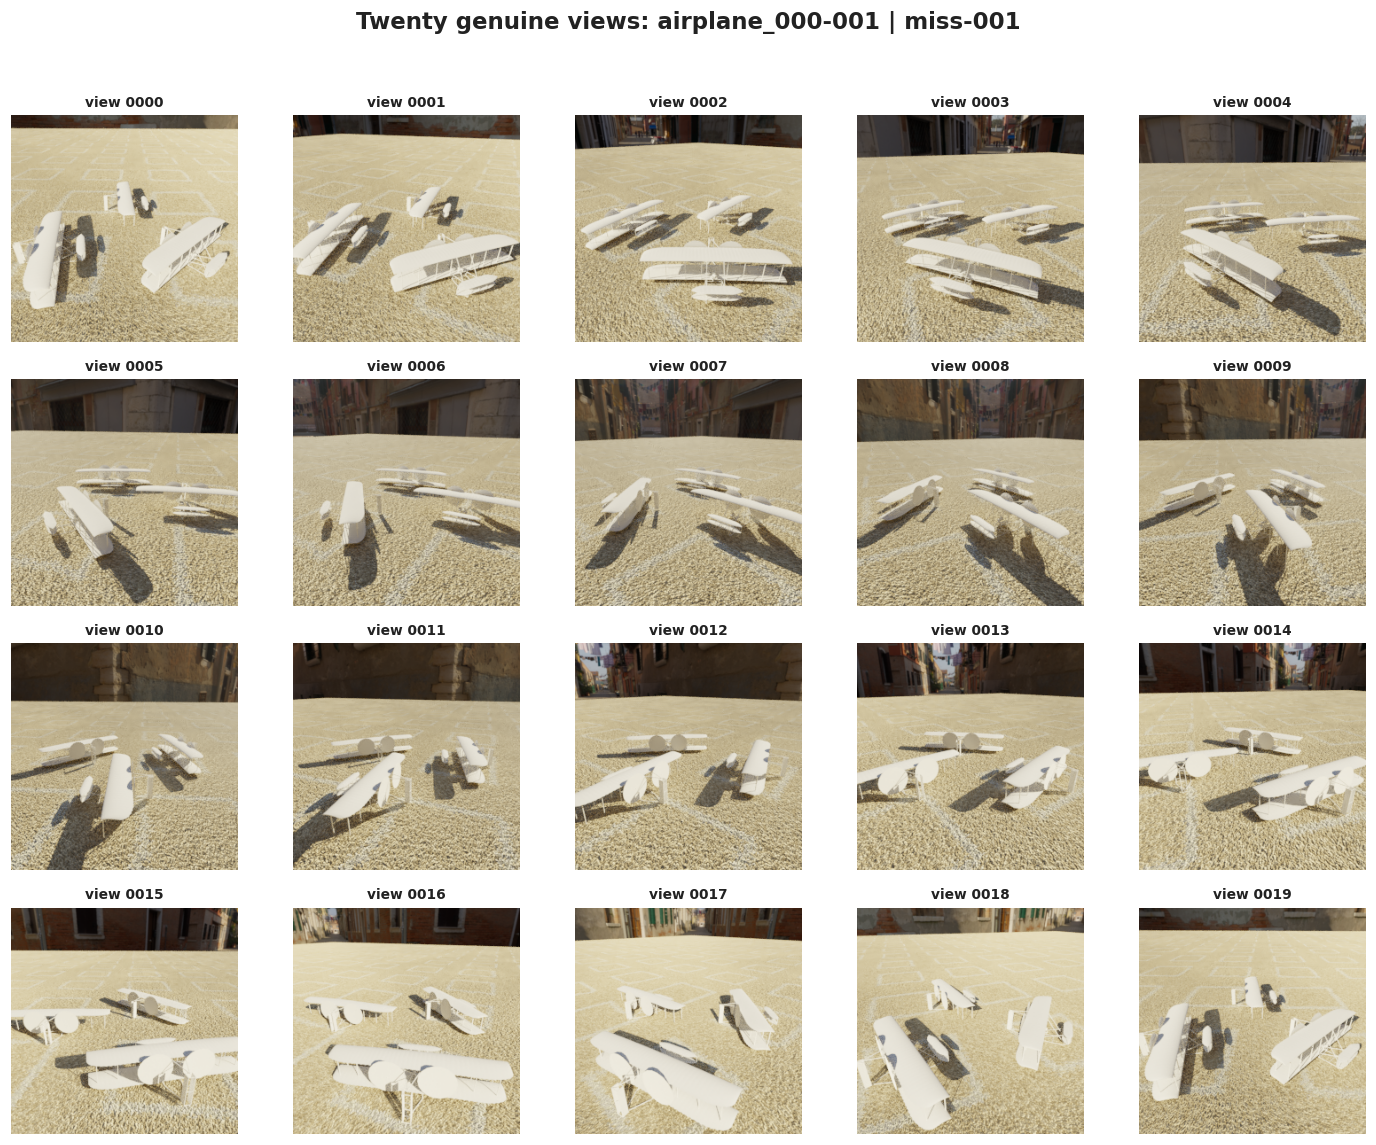

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/training_scene_twenty_views.png')

In [14]:
def paint_twenty_view_scene(scene_id: str) -> Path:
    """Display all 20 genuine camera views from the active source storage."""
    view_ids = [f"{view_number:04d}" for view_number in range(20)]

    figure, axes = plt.subplots(4, 5, figsize=(13, 10.5))
    for axis, view_id in zip(axes.flat, view_ids):
        rgb_member = f"toysad8k/{scene_id}/RGB/{view_id}.png"
        axis.imshow(read_complete_image(rgb_member, mode="RGB"))
        axis.set_title(f"view {view_id}", fontsize=9)
        axis.axis("off")

    scene = scene_lookup[scene_id]
    variants = ", ".join(scene["anomaly_variants"])
    figure.suptitle(
        f"Twenty genuine views: {scene_id} | {variants}",
        fontsize=15,
        fontweight="bold",
        y=0.99,
    )
    figure.tight_layout(rect=[0, 0, 1, 0.97])
    destination = save_eda_figure(figure, "training_scene_twenty_views.png")
    plt.show()
    plt.close(figure)
    return destination


paint_twenty_view_scene("airplane_000-001")

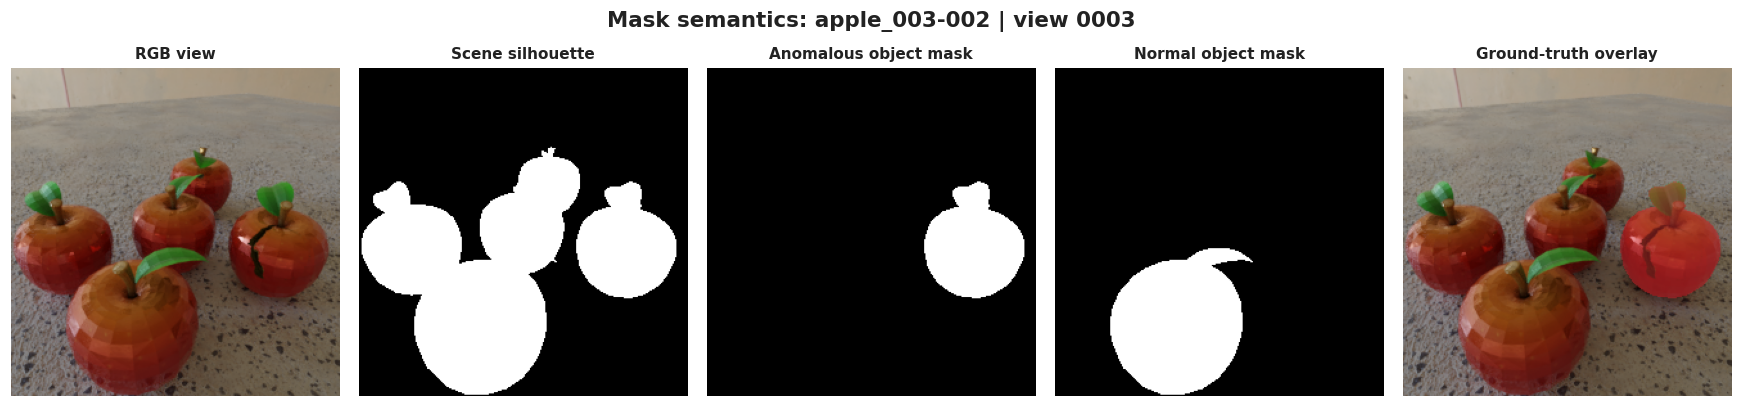

PosixPath('/kaggle/working/toysad8k_full_dataset_eda/training_mask_semantics.png')

In [15]:
def paint_mask_semantics(scene_id: str, view_id: str) -> Path:
    """Compare RGB, scene silhouette, object masks, and a ground-truth overlay."""
    scene_root = f"toysad8k/{scene_id}"
    scene3d = read_complete_json(f"{scene_root}/scene3d.metadata.json")
    scene = scene_lookup[scene_id]

    rgb = read_complete_image(f"{scene_root}/RGB/{view_id}.png", mode="RGB")
    scene_mask = read_complete_image(f"{scene_root}/masks/{view_id}.png", mode="L")

    anomaly_index = scene["anomaly_object_indices"][0]
    anomaly_name = scene3d["objects"][anomaly_index]["name"]
    anomaly_member = f"{scene_root}/segmentations/{anomaly_name}/{anomaly_name}_{view_id}.png"
    anomaly_mask = read_object_mask(anomaly_member)

    normal_index = next(index for index in range(scene["object_count"]) if index not in scene["anomaly_object_indices"])
    normal_name = scene3d["objects"][normal_index]["name"]
    normal_member = f"{scene_root}/segmentations/{normal_name}/{normal_name}_{view_id}.png"
    normal_mask = read_object_mask(normal_member)

    panels = [
        (rgb, "RGB view", None),
        (scene_mask, "Scene silhouette", "gray"),
        (anomaly_mask, "Anomalous object mask", "gray"),
        (normal_mask, "Normal object mask", "gray"),
        (tint_anomaly_region(rgb, anomaly_mask), "Ground-truth overlay", None),
    ]

    figure, axes = plt.subplots(1, 5, figsize=(16, 3.8))
    for axis, (panel, title, colour_map) in zip(axes, panels):
        axis.imshow(panel, cmap=colour_map)
        axis.set_title(title, fontsize=10)
        axis.axis("off")

    figure.suptitle(
        f"Mask semantics: {scene_id} | view {view_id}",
        fontsize=14,
        fontweight="bold",
    )
    figure.tight_layout()
    destination = save_eda_figure(figure, "training_mask_semantics.png")
    plt.show()
    plt.close(figure)
    return destination


paint_mask_semantics("apple_003-002", "0003")

## 11. Eligibility bridge for later experiment selection

This section does not select the final 2,000 scenes. It explains the reproducible filters that reduce the complete catalogue to the leakage-safe train-derived pool. The 2,000-scene selection requires a second EDA after the exact scene list is frozen.

,stage,stage_name,rule,scene_count,removed_at_stage,base_asset_count,category_count
0,1,Full scene2d catalogue,Starting point,7396,0,974,51
1,2,Official train split,Remove all non-train scenes,4238,3158,578,40
2,3,Availability-ready train,Remove train scenes with archive warnings,4224,14,578,40
3,4,Leakage-safe eligible pool,Remove train assets also present in seen-test,4107,117,545,39


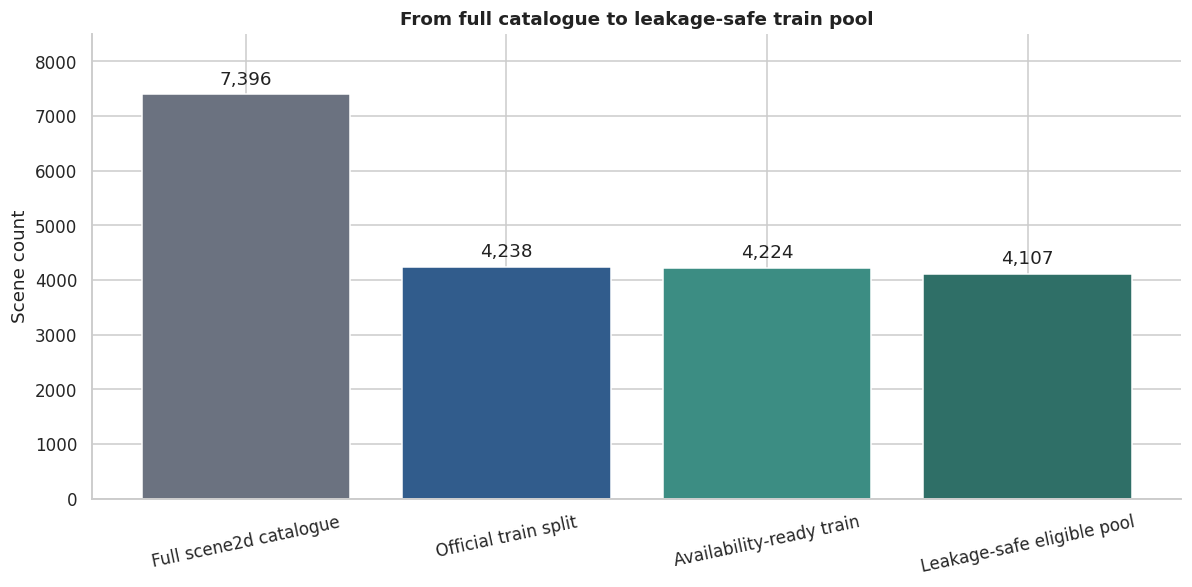

,object_count,anomaly_count,scene_count
0,3,1,2025
1,4,1,883
2,4,2,386
3,5,1,582
4,5,2,231


In [16]:
def build_experiment_eligibility_bridge(scene_frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply protocol filters in order and report the remaining scenes, assets, and categories."""
    all_scenes = scene_frame.copy()
    train_scenes = all_scenes.loc[all_scenes["split"] == "train"].copy()
    ready_train = train_scenes.loc[train_scenes["availability_ok"]].copy()

    seen_assets = set(
        all_scenes.loc[all_scenes["split"] == "seen-test", "base_asset_id"]
    )
    eligible_train = ready_train.loc[~ready_train["base_asset_id"].isin(seen_assets)].copy()

    stages = [
        ("Full scene2d catalogue", all_scenes, "Starting point"),
        ("Official train split", train_scenes, "Remove all non-train scenes"),
        ("Availability-ready train", ready_train, "Remove train scenes with archive warnings"),
        ("Leakage-safe eligible pool", eligible_train, "Remove train assets also present in seen-test"),
    ]

    rows = []
    previous_count = None
    for stage_number, (stage_name, stage_frame, rule) in enumerate(stages, start=1):
        current_count = len(stage_frame)
        rows.append({
            "stage": stage_number,
            "stage_name": stage_name,
            "rule": rule,
            "scene_count": current_count,
            "removed_at_stage": 0 if previous_count is None else previous_count - current_count,
            "base_asset_count": stage_frame["base_asset_id"].nunique(),
            "category_count": stage_frame["category"].nunique(),
        })
        previous_count = current_count

    return pd.DataFrame(rows), eligible_train


def paint_eligibility_bridge(bridge_frame: pd.DataFrame) -> Path:
    """Plot the ordered scene counts leading to the eligible pool."""
    figure, axis = plt.subplots(figsize=(11, 5.5))
    colours = ["#6B7280", "#315C8C", "#3C8D83", "#2F6F67"]
    bars = axis.bar(bridge_frame["stage_name"], bridge_frame["scene_count"], color=colours)
    axis.bar_label(bars, labels=[f"{value:,}" for value in bridge_frame["scene_count"]], padding=4)
    axis.set_title("From full catalogue to leakage-safe train pool")
    axis.set_xlabel("")
    axis.set_ylabel("Scene count")
    axis.tick_params(axis="x", rotation=12)
    axis.set_ylim(0, bridge_frame["scene_count"].max() * 1.15)
    sns.despine(ax=axis)
    figure.tight_layout()
    destination = save_eda_figure(figure, "eligibility_bridge.png")
    plt.show()
    plt.close(figure)
    return destination


eligibility_bridge, eligible_train_pool = build_experiment_eligibility_bridge(scene_table)
display(eligibility_bridge)
save_eda_table(eligibility_bridge, "eligibility_bridge.csv")
paint_eligibility_bridge(eligibility_bridge)

eligible_structure = (
    eligible_train_pool.groupby(["object_count", "anomaly_count"], observed=True)
    .size()
    .rename("scene_count")
    .reset_index()
    .sort_values(["object_count", "anomaly_count"])
)
display(eligible_structure)
save_eda_table(eligible_structure, "eligible_pool_scene_structure.csv")

assert len(eligible_train_pool) == 4107
assert eligible_train_pool["base_asset_id"].nunique() == 545
assert eligible_train_pool["category"].nunique() == 39

## 12. Findings and next action

The notebook separates three claims:

1. What the complete catalogue contains.
2. What archive quality warnings are present.
3. What remains eligible for a train-derived experiment.

The next dataset notebook should start only after the exact 2,000-scene manifest is frozen. It should compare the selected subset with the 4,107-scene eligible pool by category, base asset, object count, anomaly count, anomaly family, and scene role. It must not redraw or tune the official tests.

In [17]:
def print_toysad_eda_findings(
    scene_frame: pd.DataFrame,
    object_frame: pd.DataFrame,
    eligible_frame: pd.DataFrame,
) -> None:
    """Print the main EDA findings in short, report-ready statements."""
    statements = [
        f"The complete scene2d catalogue contains {len(scene_frame):,} scenes across {scene_frame['category'].nunique()} categories.",
        f"The catalogue represents {scene_frame['base_asset_id'].nunique():,} base assets and {len(object_frame):,} peer objects.",
        f"There are {int(object_frame['is_anomaly'].sum()):,} anomalous objects and no native all-normal scenes.",
        f"{int(scene_frame['availability_ok'].sum()):,} scenes are availability-ready; {int((~scene_frame['availability_ok']).sum()):,} scenes carry one or more warnings.",
        f"All {expected_raw_image_files:,} PNG and EXR members were checked; {len(full_image_header_failures):,} are zero-byte image files and every non-empty image is 256 x 256.",
        "All anomalous objects are first in source order, so object order and source names must be hidden from models.",
        f"The leakage-safe train-derived pool contains {len(eligible_frame):,} scenes, {eligible_frame['base_asset_id'].nunique()} assets, and {eligible_frame['category'].nunique()} categories.",
        "Official test pixels were not displayed; their raw file headers and aggregate counts were audited.",
        "Supplied segmentations are whole-object references, not defect masks.",
    ]
    for number, statement in enumerate(statements, start=1):
        print(f"{number}. {statement}")


print_toysad_eda_findings(scene_table, object_table, eligible_train_pool)

1. The complete scene2d catalogue contains 7,396 scenes across 51 categories.
2. The catalogue represents 974 base assets and 27,290 peer objects.
3. There are 8,482 anomalous objects and no native all-normal scenes.
4. 7,373 scenes are availability-ready; 23 scenes carry one or more warnings.
5. All 1,139,416 PNG and EXR members were checked; 11 are zero-byte image files and every non-empty image is 256 x 256.
6. All anomalous objects are first in source order, so object order and source names must be hidden from models.
7. The leakage-safe train-derived pool contains 4,107 scenes, 545 assets, and 39 categories.
8. Official test pixels were not displayed; their raw file headers and aggregate counts were audited.
9. Supplied segmentations are whole-object references, not defect masks.


## 13. Run record and generated artifacts

The final cell records source hashes, package versions, derived totals, and hashes for every generated table and figure. This makes later supervisor updates traceable to one EDA run.

In [18]:
def build_output_artifact_register(output_dir: Path) -> pd.DataFrame:
    """Hash generated EDA artifacts, excluding the register itself."""
    rows = []
    for path in sorted(output_dir.iterdir()):
        if not path.is_file() or path.name == "eda_artifact_manifest.csv":
            continue
        rows.append({
            "artifact": path.name,
            "bytes": path.stat().st_size,
            "sha256": source_sha256(path),
        })
    return pd.DataFrame(rows)


REFERENCE_DERIVED_COUNTS = {
    "catalogue_scenes": 7396,
    "categories": 51,
    "base_assets": 974,
    "objects": 27290,
    "anomalous_objects": 8482,
    "availability_ready_scenes": 7373,
    "indexed_files": 1161604,
    "validated_png_and_exr_headers": 1139405,
    "image_header_failures": 11,
    "eligible_train_scenes": 4107,
    "eligible_train_assets": 545,
    "eligible_train_categories": 39,
}


run_record = {
    "notebook": "01_toysad8k_full_dataset_eda.ipynb",
    "executed_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "scope": "complete 7396-scene catalogue and all indexed PNG and EXR headers",
    "storage_mode": STORAGE_MODE,
    "source_hashes": {
        row["source"]: row["sha256"] for row in source_register.to_dict("records")
    },
    "environment": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": sns.__version__,
        "pillow": getattr(PillowImage, "__version__", None),
    },
    "derived_counts": {
        "catalogue_scenes": len(scene_table),
        "categories": int(scene_table["category"].nunique()),
        "base_assets": int(scene_table["base_asset_id"].nunique()),
        "objects": len(object_table),
        "anomalous_objects": int(object_table["is_anomaly"].sum()),
        "availability_ready_scenes": int(scene_table["availability_ok"].sum()),
        "indexed_files": int(archive_modality_inventory["file_count"].sum()),
        "validated_png_and_exr_headers": int(full_image_header_profile["file_count"].sum()),
        "image_header_failures": len(full_image_header_failures),
        "eligible_train_scenes": len(eligible_train_pool),
        "eligible_train_assets": int(eligible_train_pool["base_asset_id"].nunique()),
        "eligible_train_categories": int(eligible_train_pool["category"].nunique()),
    },
    "protocol_notes": [
        "Scenes are statistical units.",
        "Views are repeated observations.",
        "Train-derived roles must be grouped by base_asset_id.",
        "Official test pixels were not displayed or interpreted.",
        "Object order and source identifiers are leakage fields.",
        "No native all-normal scenes are present.",
    ],
}

equivalence_rows = [
    {
        "measure": measure,
        "local_reference": expected_value,
        "current_run": run_record["derived_counts"][measure],
        "matches": expected_value == run_record["derived_counts"][measure],
    }
    for measure, expected_value in REFERENCE_DERIVED_COUNTS.items()
]
cross_environment_equivalence = pd.DataFrame(equivalence_rows)
assert bool(cross_environment_equivalence["matches"].all())
run_record["cross_environment_reference_match"] = True
display(cross_environment_equivalence)
save_eda_table(cross_environment_equivalence, "cross_environment_equivalence.csv")

run_record_path = OUTPUT_DIR / "run_record.json"
with run_record_path.open("w", encoding="utf-8") as handle:
    json.dump(run_record, handle, indent=2)
    handle.write("\n")

if ARCHIVE_READER is not None:
    ARCHIVE_READER.close()
    ARCHIVE_READER = None

artifact_register = build_output_artifact_register(OUTPUT_DIR)
save_eda_table(artifact_register, "eda_artifact_manifest.csv")

display(artifact_register)
print(f"Generated {len(artifact_register):,} hashed artifacts plus the artifact manifest.")
print(f"Run record: {run_record_path}")

,measure,local_reference,current_run,matches
0,catalogue_scenes,7396,7396,True
1,categories,51,51,True
2,base_assets,974,974,True
3,objects,27290,27290,True
4,anomalous_objects,8482,8482,True
5,availability_ready_scenes,7373,7373,True
6,indexed_files,1161604,1161604,True
7,validated_png_and_exr_headers,1139405,1139405,True
8,image_header_failures,11,11,True
9,eligible_train_scenes,4107,4107,True


,artifact,bytes,sha256
0,anomaly_family_by_split.csv,261,b4d9e2ae6aa2c7869cde0189a94e1af3c8b61f45847ec6...
1,anomaly_family_counts.png,68707,5c803c0d856afbe5b2dd51315cb3ec5d7d7fec08a7b8c1...
2,anomaly_variant_summary.csv,820,937a0ea2d04a8a9ddcbfe8562ec9a873be6e5f7e7159a3...
3,archive_modality_inventory.csv,513,40d871d051f762385113190e09ca675f18e6bf1ab3b74c...
4,archive_modality_inventory.png,85225,bd6f91b9011a4cee971afc0ea5b5b02292d928ac78cdeb...
5,availability_issue_by_split.csv,246,80edc8f730f08f318debc9a64209d88d448073b0f94a03...
6,availability_overview.csv,100,e62d12bad2147c5f8fede3d2976a920702f8a2e78fd2c2...
7,availability_warnings.png,75632,10a4272d0f82288887836683f1f26eed93ba50aa8d9b82...
8,base_asset_overlap.csv,150,17e2f7522d22bb0d7c2a221c869079c7faa520d0b96367...
9,base_asset_profile.png,110571,0e6a888d1276ae28bd79a90619f634b76d9767801e14fe...


Generated 35 hashed artifacts plus the artifact manifest.
Run record: /kaggle/working/toysad8k_full_dataset_eda/run_record.json


## End of notebook

All displayed examples came from the training split and were read from the same validated archive payload. The full EDA can be reproduced from the source hashes and storage mode recorded in the output folder.